# ResNet50 V29 — Real Healthy Train target = 30

Controlled experiment derived from the **unexecuted V28 256×256 transfer recipe**.
The only training-data change is a fixed offline augmentation of `real_`-named
Healthy images in Train to a total target of 30 (originals included).
The ResNet50 architecture, ImageNet initialization, 5 seeds, online augmentation,
optimizer, learning rates, batch size, stages, 18/16 maximum epochs, callbacks,
preprocessing, and frozen Split (11) are unchanged.

The source ZIP is immutable. Synthetic images live only in the V29 result
folder and are appended to the Train file list before all 5 seeds. This run
uses the project's `real_` filename convention as the source rule. It checks
the frozen ZIP, split, class and duplicate filenames before augmentation.
The convention does not establish leaf_id/tree_id or capture provenance.

This is Validation-only target tuning. Final Test and Real Holdout flags are
disabled by default; both remain available only as a later final evaluation
after the Validation selection lock. Run cells top-to-bottom on a Colab GPU.


In [1]:
import sys
print("Python:", sys.executable)
!pip install -q google-api-python-client google-auth-httplib2
!nvidia-smi


Python: /usr/bin/python3
Fri Oct 30 07:01:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   37C    P0             88W /  600W |    2639MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+----------------------

In [2]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import base64
import zlib
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

plt.rcParams.update({
    "text.color": "black", "axes.labelcolor": "black",
    "axes.titlecolor": "black", "xtick.color": "black", "ytick.color": "black",
})

print("Imports completed.")

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")


Imports completed.


In [3]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
try:
    import google.colab
except ImportError as exc:
    raise RuntimeError("EXP-029 runs on Google Colab with Google Drive authentication") from exc
RUNTIME = "Colab"
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    print("CPU runtime detected; VIEW_ONLY can continue, model smoke/training requires GPU.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if gpus:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-30 07:02:00
Python            : 3.13.16
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.159+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [4]:

# ============================================================
# 03. CONFIGURATION — EXP-029
# ============================================================

NOTEBOOK_VERSION = "29"
CODE_REVISION_SHA256 = "bccd13654cdeaa412bd6430401512764d081480d9e83f058ae2924c6f6687f6c"
NOTEBOOK_SOURCE_PATH = None  # Optional path to this exact V29 .ipynb on Drive.
IMG_SIZE = 256  # Bilinear input resize for this experiment.
EXPERIMENT_ID = "EXP-RESNET50-TRANSFER-5SEEDS-029"
DATASET_VERSION = "Cashew_dataV11"
DATASET_ARCHIVE_NAME = "CashewData_Split (11).zip"
DATASET_ARCHIVE_FILE_ID = "1rq2qBwdQbaL4MSUMSFfRp2QnIQxyI-xt"
DRIVE_DATASET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"
DRIVE_HOLDOUT_FILE_ID = "1LCESEVpZvS7Yp0eWnLZKheeatI24KaZ5"
DRIVE_RESULTS_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"
DRIVE_RUN_FOLDER_ID = None  # Resolved by experiment name in current_dataset.


DRIVE_TARGET_URL = (
    "https://drive.google.com/drive/folders/"
    "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing"
)
DRIVE_TARGET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"

EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "red_rust",
    "not_cashew_leaf",
]

EXPECTED_COUNTS = {
    "anthracnose": {"train": 982, "val": 309, "test": 120, "total": 1411},
    "healthy": {"train": 830, "val": 222, "test": 118, "total": 1170},
    "leaf_miner": {"train": 875, "val": 267, "test": 130, "total": 1272},
    "not_cashew_leaf": {"train": 1102, "val": 314, "test": 156, "total": 1572},
    "red_rust": {"train": 1127, "val": 335, "test": 161, "total": 1623},
}
EXPECTED_TOTALS = {"train": 4916, "val": 1447, "test": 685, "total": 7048}
STRICT_DATASET_CHECK = True
EXPECTED_REAL_FILENAME_COUNTS = {"train": 238, "val": 54, "test": 28}
REQUIRED_ABSENT_IMAGES = []  # The Split (11) ZIP hash freezes exact membership.

# ------------------------------------------------------------
# Fixed five-seed, two-stage transfer protocol
# ------------------------------------------------------------
SEEDS = [42, 123, 2026, 3407, 7777]
if IMG_SIZE != 256:
    raise ValueError("EXP-029 requires 256x256 input")
BATCH_SIZE = 16
MODEL_NAME = "ResNet50"
TRAINING_MODE = "ImageNet Transfer, two-stage"
PRETRAINED_WEIGHTS = "imagenet"
HEAD_DROPOUT = 0.40
WEIGHT_DECAY = 1e-4
STAGE1_LR, STAGE1_EPOCHS = 1e-4, 18
STAGE1_EARLY_PATIENCE, STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR = 5, 2, 1e-6
STAGE2_LR, STAGE2_EPOCHS = 3e-6, 16
STAGE2_EARLY_PATIENCE, STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR = 3, 2, 1e-7

# V29 data intervention; source is identified by the real_ filename prefix.
ENABLE_REAL_HEALTHY_TARGET_AUG = True
TARGET_REAL_HEALTHY_TRAIN = 30  # Originals + generated images, not 30 additions.
OFFLINE_AUG_SEED = 2029
PREVIOUS_EXPERIMENT_DIR = None  # Optional V28 output folder for Validation-only comparison.
LR_REDUCTION_FACTOR = 0.5
EXPECTED_ZIP_SHA256 = "5d60295d26068f5d9f6427dc730a0f662c56c28ad9ee95f8b594faf546861f49"
EXPECTED_MANIFEST_SHA256 = None  # Frozen at first audited run; ZIP SHA256 is checked above.

RUN_PIPELINE_SMOKE = True
VIEW_ONLY = False
RUN_SMOKE_ONLY = False
RUN_FULL_TRAINING = True
RUN_FINAL_TEST = False  # Enable only for later final evaluation.
RUN_REAL_HOLDOUT = False  # Enable only after target choice is frozen.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (5).zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "8D5C3758B5869C3AE19238FA8D78E53AD15BB40544F4C70F632602896D80045F"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 46, "healthy": 13, "leaf_miner": 36, "red_rust": 25}
# Holdout is downloaded by exact Drive file ID after the Validation lock.

# Cell order enforces training -> Validation lock -> Test -> holdout.
# Dataset and holdout hashes are inherited from the verified EXP-025 audit.

# Local Colab workspace; cloud ZIPs are uploaded after the run completes.
PROJECT_ROOT = Path("/content")
RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

import google.auth
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

auth.authenticate_user()
drive_credentials, _ = google.auth.default()
drive_service = build("drive", "v3", credentials=drive_credentials,
                      cache_discovery=False)

dataset_metadata = drive_service.files().get(
    fileId=DATASET_ARCHIVE_FILE_ID,
    fields="id,name,size,md5Checksum,parents,mimeType",
    supportsAllDrives=True,
).execute()
results_folder_metadata = drive_service.files().get(
    fileId=DRIVE_RESULTS_FOLDER_ID,
    fields="id,name,mimeType,capabilities(canAddChildren)",
    supportsAllDrives=True,
).execute()
if dataset_metadata.get("name") != DATASET_ARCHIVE_NAME:
    raise ValueError("Dataset 11 file ID resolves to the wrong name")
if DRIVE_DATASET_FOLDER_ID not in dataset_metadata.get("parents", []):
    raise ValueError("Dataset 11 ZIP is no longer in the supplied Drive folder")
if results_folder_metadata.get("mimeType") != "application/vnd.google-apps.folder":
    raise ValueError("Drive results destination is not a folder")
if results_folder_metadata.get("capabilities", {}).get("canAddChildren") is False:
    raise PermissionError("This Google account cannot upload to current_dataset")

run_folders = drive_service.files().list(
    q=(f"'{DRIVE_RESULTS_FOLDER_ID}' in parents and "
       f"name = '{EXPERIMENT_ID}' and "
       "mimeType = 'application/vnd.google-apps.folder' and trashed = false"),
    fields="nextPageToken,files(id,name,mimeType,parents)", pageSize=100,
    supportsAllDrives=True, includeItemsFromAllDrives=True,
).execute()
if run_folders.get("nextPageToken") or len(run_folders.get("files", [])) > 1:
    raise RuntimeError("Ambiguous EXP-029 result folder")
if run_folders.get("files"):
    DRIVE_RUN_FOLDER_ID = run_folders["files"][0]["id"]
elif VIEW_ONLY:
    raise FileNotFoundError("EXP-029 result folder does not exist on Drive")
else:
    created_folder = drive_service.files().create(
        body={"name": EXPERIMENT_ID,
              "mimeType": "application/vnd.google-apps.folder",
              "parents": [DRIVE_RESULTS_FOLDER_ID]},
        fields="id,name,mimeType,parents", supportsAllDrives=True,
    ).execute()
    DRIVE_RUN_FOLDER_ID = created_folder["id"]
run_folder_metadata = drive_service.files().get(
    fileId=DRIVE_RUN_FOLDER_ID,
    fields="id,name,mimeType,parents,capabilities(canAddChildren)",
    supportsAllDrives=True,
).execute()
if (run_folder_metadata.get("name") != EXPERIMENT_ID or
        run_folder_metadata.get("mimeType") != "application/vnd.google-apps.folder" or
        DRIVE_RESULTS_FOLDER_ID not in run_folder_metadata.get("parents", [])):
    raise ValueError("EXP-029 result folder ID or parent changed")
if run_folder_metadata.get("capabilities", {}).get("canAddChildren") is False:
    raise PermissionError("This Google account cannot upload to EXP-029 result folder")
if RUN_FULL_TRAINING:
    existing_results = drive_service.files().list(
        q=f"'{DRIVE_RUN_FOLDER_ID}' in parents and trashed = false",
        fields="files(id,name,mimeType)", pageSize=100,
        supportsAllDrives=True, includeItemsFromAllDrives=True,
    ).execute().get("files", [])
    if any(item["name"] in {f"{EXPERIMENT_ID}_ANALYSIS.zip",
                            f"{EXPERIMENT_ID}_FULL.zip"}
           for item in existing_results):
        raise FileExistsError("EXP-029 result ZIP already exists on Drive; use a new ID")

def download_drive_archive(file_id, expected_name, destination, metadata):
    destination = Path(destination)
    if metadata.get("name") != expected_name or metadata.get("id") != file_id:
        raise ValueError("Drive archive identity changed")
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.is_file():
        temporary = destination.with_name(destination.name + ".partial")
        request = drive_service.files().get_media(fileId=file_id, supportsAllDrives=True)
        with temporary.open("wb") as stream:
            downloader = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
            done = False
            while not done:
                progress, done = downloader.next_chunk(num_retries=3)
                if progress is not None:
                    print(f"{expected_name}: {progress.progress():.0%}")
        temporary.replace(destination)
    if destination.stat().st_size != int(metadata["size"]):
        raise ValueError(f"Drive archive size mismatch: {destination}")
    if metadata.get("md5Checksum"):
        digest = hashlib.md5()
        with destination.open("rb") as stream:
            for block in iter(lambda: stream.read(8 << 20), b""):
                digest.update(block)
        if digest.hexdigest() != metadata["md5Checksum"]:
            raise ValueError(f"Drive archive MD5 mismatch: {destination}")
    return destination

print("Dataset Drive file:", dataset_metadata["name"], dataset_metadata["size"])
print("Result Drive folder:", results_folder_metadata["name"], DRIVE_RESULTS_FOLDER_ID)
print("Experiment Drive folder:", DRIVE_RUN_FOLDER_ID)

OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"
if RUN_FULL_TRAINING and OUT_DIR.exists() and any(OUT_DIR.iterdir()):
    raise RuntimeError("EXP-029 already has artifacts; use a new run ID/runtime for a fresh train")
for directory in (OUT_DIR, AGGREGATE_DIR, PANEL_DIR, MODEL_PACKAGE_DIR, CODE_PACKAGE_DIR, ENV_DIR):
    if VIEW_ONLY:
        if not directory.is_dir(): raise FileNotFoundError(directory)
    else:
        directory.mkdir(parents=True, exist_ok=True)
if VIEW_ONLY and (RUN_SMOKE_ONLY or RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT):
    raise ValueError("VIEW_ONLY requires all run flags False")
if RUNTIME == "Colab" and not gpus and not VIEW_ONLY:
    raise RuntimeError("Select a Colab GPU runtime for model smoke/training")
if RUN_SMOKE_ONLY and (RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT):
    raise ValueError("Disable RUN_SMOKE_ONLY explicitly for training/evaluation")
if (RUN_FINAL_TEST or RUN_REAL_HOLDOUT or VIEW_ONLY) and not (RUN_FULL_TRAINING or (OUT_DIR / "validation_selection_lock.json").is_file()):
    raise FileNotFoundError("A completed EXP-029 Validation lock is required")
print("Experiment:", EXPERIMENT_ID)
print("Dataset:", DATASET_ARCHIVE_NAME, "| seeds:", SEEDS)
print("Flags:", RUN_FULL_TRAINING, RUN_FINAL_TEST, RUN_REAL_HOLDOUT)


Dataset Drive file: CashewData_Split (11).zip 1464151244
Result Drive folder: current_dataset 1DGKTnzsvVc60RIEn5lQgflR3s-loM24G
Experiment Drive folder: 1Nknk-0GmFTla0-cYCk-9qpuDAL0vhWSf
Experiment: EXP-RESNET50-TRANSFER-5SEEDS-029
Dataset: CashewData_Split (11).zip | seeds: [42, 123, 2026, 3407, 7777]
Flags: True False False


In [5]:
if not VIEW_ONLY:

    # ============================================================
    # 04. REPRODUCIBILITY
    # ============================================================

    def set_global_seed(seed: int):
        os.environ["PYTHONHASHSEED"] = str(seed)

        random.seed(seed)
        np.random.seed(seed)
        tf.random.set_seed(seed)

        # Đồng bộ Python / NumPy / TensorFlow theo Keras.
        try:
            keras.utils.set_random_seed(seed)
        except Exception:
            pass

        print(f"Global seed set to: {seed}")


    try:
        tf.config.experimental.enable_op_determinism()
        print("Deterministic operations: ENABLED")
    except Exception as e:
        print("Deterministic operations: unavailable")
        print("Reason:", e)
else:
    print('Cell 5 skipped in VIEW_ONLY')


Deterministic operations: ENABLED


In [6]:
if not VIEW_ONLY:
    # ============================================================
    # 05. LOAD FROZEN SPLIT (11) FROM ITS EXACT DRIVE FILE ID
    # ============================================================

    # EXPECTED_ZIP_SHA256 is defined in the configuration cell.

    archive_for_hash = download_drive_archive(
        DATASET_ARCHIVE_FILE_ID, DATASET_ARCHIVE_NAME,
        PROJECT_ROOT / "dataset_archives" / DATASET_ARCHIVE_NAME,
        dataset_metadata,
    )

    digest = hashlib.sha256()
    with archive_for_hash.open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    DATASET_ZIP_SHA256 = digest.hexdigest()
    if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256:
        raise ValueError(
            f"Split (11) ZIP SHA256 mismatch: {DATASET_ZIP_SHA256}; "
            f"expected {EXPECTED_ZIP_SHA256}"
        )
    print("Verified Split (11) ZIP:", archive_for_hash)
    print("Dataset ZIP SHA256:", DATASET_ZIP_SHA256)

    # Keep this cache separate from the Split (7) dataset used by version 011.
    cache_parent = PROJECT_ROOT / "dataset_cache"
    extraction_root = cache_parent / "split_11"
    staging_root = cache_parent / "split_11_staging"
    DATASET_PATH = extraction_root / "CashewData_Split"
    marker = extraction_root / ".archive_sha256"

    if extraction_root.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != EXPECTED_ZIP_SHA256:
            raise RuntimeError(
                f"Split (11) cache has no matching completion marker: {extraction_root}. "
                "Inspect it and remove or rename it before retrying."
            )
    else:
        if staging_root.exists():
            raise RuntimeError(
                f"Previous Split (11) extraction is incomplete: {staging_root}. "
                "Inspect it and remove or rename it before retrying."
            )
        cache_parent.mkdir(parents=True, exist_ok=True)
        staging_root.mkdir()
        with zipfile.ZipFile(archive_for_hash) as dataset_archive:
            for member in dataset_archive.infolist():
                target = (staging_root / member.filename).resolve()
                if target != staging_root.resolve() and staging_root.resolve() not in target.parents:
                    raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
                if not member.filename.startswith("CashewData_Split/"):
                    raise ValueError(f"Unexpected Split (11) ZIP root: {member.filename}")
            print("Extracting Split (11) into:", staging_root)
            dataset_archive.extractall(staging_root)
        if not all((staging_root / "CashewData_Split" / name).is_dir()
                   for name in ("train", "val", "test")):
            raise RuntimeError("Split (11) ZIP has no complete train/val/test directory tree.")
        (staging_root / ".archive_sha256").write_text(EXPECTED_ZIP_SHA256 + "\n", encoding="utf-8")
        staging_root.rename(extraction_root)

    required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
    missing_splits = [str(path) for path in required_splits if not path.is_dir()]
    if missing_splits:
        raise FileNotFoundError(f"Split (11) cache is incomplete: {missing_splits}")

    TRAIN_DIR = DATASET_PATH / "train"
    VAL_DIR = DATASET_PATH / "val"
    TEST_DIR = DATASET_PATH / "test"

    unexpected_removed_files = [
        DATASET_PATH / Path(relative_path)
        for relative_path in REQUIRED_ABSENT_IMAGES
        if (DATASET_PATH / Path(relative_path)).is_file()
    ]
    if unexpected_removed_files:
        raise ValueError(
            "Split (11) contains files that should be absent:\n" +
            "\n".join(str(path) for path in unexpected_removed_files)
        )

    print("\nSelected dataset:", DATASET_PATH)
    print("TRAIN_DIR:", TRAIN_DIR)
    print("VAL_DIR  :", VAL_DIR)
    print("TEST_DIR :", TEST_DIR)
else:
    print('Cell 6 skipped in VIEW_ONLY')


Verified Split (11) ZIP: /content/dataset_archives/CashewData_Split (11).zip
Dataset ZIP SHA256: 5d60295d26068f5d9f6427dc730a0f662c56c28ad9ee95f8b594faf546861f49

Selected dataset: /content/dataset_cache/split_11/CashewData_Split
TRAIN_DIR: /content/dataset_cache/split_11/CashewData_Split/train
VAL_DIR  : /content/dataset_cache/split_11/CashewData_Split/val
TEST_DIR : /content/dataset_cache/split_11/CashewData_Split/test



# Dataset Audit

Notebook kiểm tra lại toàn bộ ảnh trước khi train.

Nếu:
- có ảnh decode lỗi;
- có file extension lạ;
- class folder sai;
- số lượng khác revision sạch trong `CashewData_Split (11).zip`;

thì notebook sẽ **dừng** khi `STRICT_DATASET_CHECK=True`.


In [7]:
if not VIEW_ONLY:

    # ============================================================
    # 06. DATASET AUDIT + EXACT COUNTS
    # ============================================================

    VALID_EXTENSIONS = {
        ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
    }


    def sha256_file(path):
        digest = hashlib.sha256()
        with open(path, "rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()


    from PIL import ImageOps
    from scipy.fftpack import dct


    def phash64(image):
        gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
        frequencies = dct(dct(gray, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8]
        bits = frequencies > np.median(frequencies)
        return int("".join("1" if bit else "0" for bit in bits.flat), 2)


    def pixel_hash(image):
        rgb = image.convert("RGB")
        digest = hashlib.sha256()
        digest.update(f"{rgb.width}x{rgb.height}:".encode())
        digest.update(rgb.tobytes())
        return digest.hexdigest()


    def audit_split(split_name, split_dir):
        valid_rows = []
        bad_rows = []
        unknown_rows = []

        found_classes = sorted([
            p.name for p in split_dir.iterdir()
            if p.is_dir()
        ])

        if found_classes != sorted(EXPECTED_CLASSES):
            raise ValueError(
                f"Class folders của {split_name} không đúng.\n"
                f"Expected: {sorted(EXPECTED_CLASSES)}\n"
                f"Found   : {found_classes}"
            )

        for label, class_name in enumerate(EXPECTED_CLASSES):
            class_dir = split_dir / class_name

            for path in sorted(class_dir.rglob("*")):
                if not path.is_file():
                    continue

                ext = path.suffix.lower()

                if ext not in VALID_EXTENSIONS:
                    unknown_rows.append({
                        "split": split_name,
                        "class": class_name,
                        "path": str(path),
                        "extension": ext,
                    })
                    continue

                try:
                    with Image.open(path) as img:
                        img.verify()

                    with Image.open(path) as img:
                        image = ImageOps.exif_transpose(img)
                        image.load()
                        pixels_sha = pixel_hash(image)
                        perceptual_hash = phash64(image)

                    valid_rows.append({
                        "split": split_name,
                        "class": class_name,
                        "label": label,
                        "path": str(path),
                        "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                        "sha256": sha256_file(path),
                        "pixel_sha256": pixels_sha,
                        "phash64": perceptual_hash,
                        "is_real_filename": path.name.casefold().startswith("real_"),
                    })

                except Exception as e:
                    bad_rows.append({
                        "split": split_name,
                        "class": class_name,
                        "path": str(path),
                        "error": str(e),
                    })

        return valid_rows, bad_rows, unknown_rows


    all_valid = []
    all_bad = []
    all_unknown = []

    for split_name, split_dir in {
        "train": TRAIN_DIR,
        "val": VAL_DIR,
        "test": TEST_DIR,
    }.items():

        print(f"Checking {split_name}...")

        valid_rows, bad_rows, unknown_rows = audit_split(
            split_name,
            split_dir
        )

        all_valid.extend(valid_rows)
        all_bad.extend(bad_rows)
        all_unknown.extend(unknown_rows)


    valid_df = pd.DataFrame(all_valid)
    bad_df = pd.DataFrame(all_bad)
    unknown_df = pd.DataFrame(all_unknown)

    print("\n" + "=" * 70)
    print("VALID IMAGES   :", len(valid_df))
    print("INVALID IMAGES :", len(bad_df))
    print("UNKNOWN FILES  :", len(unknown_df))
    print("=" * 70)

    if len(bad_df):
        display(bad_df)

    if len(unknown_df):
        display(unknown_df)

    bad_df.to_csv(OUT_DIR / "invalid_images.csv", index=False)
    unknown_df.to_csv(OUT_DIR / "unknown_files.csv", index=False)

    if len(bad_df):
        raise ValueError("Dataset còn ảnh lỗi. Hãy clean dataset trước khi train.")

    if len(unknown_df):
        raise ValueError("Dataset có file extension lạ. Hãy kiểm tra trước khi train.")


    stats_df = (
        valid_df.groupby(["class", "split"])
        .size()
        .unstack(fill_value=0)
        .reindex(EXPECTED_CLASSES)
    )

    for col in ["train", "val", "test"]:
        if col not in stats_df.columns:
            stats_df[col] = 0

    stats_df = stats_df[["train", "val", "test"]]
    stats_df["total"] = stats_df.sum(axis=1)

    display(stats_df)

    actual_totals = {
        "train": int(stats_df["train"].sum()),
        "val": int(stats_df["val"].sum()),
        "test": int(stats_df["test"].sum()),
        "total": int(stats_df["total"].sum()),
    }

    mismatches = []

    for class_name in EXPECTED_CLASSES:
        for split_name in ["train", "val", "test", "total"]:

            actual = int(stats_df.loc[class_name, split_name])
            expected = int(EXPECTED_COUNTS[class_name][split_name])

            if actual != expected:
                mismatches.append({
                    "class": class_name,
                    "split": split_name,
                    "actual": actual,
                    "expected": expected,
                })

    for split_name in ["train", "val", "test", "total"]:
        if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
            mismatches.append({
                "class": "TOTAL",
                "split": split_name,
                "actual": actual_totals[split_name],
                "expected": EXPECTED_TOTALS[split_name],
            })

    if mismatches:
        mismatch_df = pd.DataFrame(mismatches)
        display(mismatch_df)

        if STRICT_DATASET_CHECK:
            raise ValueError(
                "Dataset count does not match the frozen Split (11) archive."
            )
    else:
        print("Dataset counts match the frozen Split (11) archive.")
        print(actual_totals)


    # Save manifest để biết chính xác file nào thuộc split nào.
    valid_df.to_csv(
        OUT_DIR / "dataset_manifest.csv",
        index=False
    )


    manifest_records = valid_df[["relative_path", "label", "sha256"]].to_dict("records")
    DATASET_MANIFEST_SHA256 = hashlib.sha256(
        json.dumps(manifest_records, sort_keys=True, separators=(",", ":")).encode()
    ).hexdigest()
    (OUT_DIR / "dataset_manifest_sha256.txt").write_text(DATASET_MANIFEST_SHA256 + "\n", encoding="utf-8")
    print("Dataset manifest SHA256:", DATASET_MANIFEST_SHA256)
    if EXPECTED_MANIFEST_SHA256 is not None and DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256:
        raise ValueError("Frozen Split (11) manifest SHA256 mismatch")


    real_counts = (valid_df.groupby("split")["is_real_filename"]
                   .agg(["sum", "count"]).reindex(["train", "val", "test"]))
    actual_real_counts = {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")}
    if actual_real_counts != EXPECTED_REAL_FILENAME_COUNTS:
        raise ValueError(
            f"Split (11) real_ filename counts mismatch: {actual_real_counts}; "
            f"expected {EXPECTED_REAL_FILENAME_COUNTS}"
        )
    real_counts.to_csv(OUT_DIR / "real_filename_counts_by_split.csv")
    real_class_counts = (valid_df.groupby(["split", "class"])["is_real_filename"]
                         .agg(["sum", "count"]))
    real_class_counts.to_csv(OUT_DIR / "real_filename_counts_by_split_class.csv")
    print("real_ filename counts:")
    display(real_counts)
    if int(real_counts.loc["val", "sum"]) == 0:
        print("WARNING: Validation has no real_ filename; checkpoints cannot be selected for this group.")

    exact_rows = []
    for digest_column in ("sha256", "pixel_sha256"):
        for _, group in valid_df.groupby(digest_column, sort=False):
            if len(group) < 2:
                continue
            records = group[["relative_path", "split", "class"]].to_dict("records")
            for a_index in range(len(records)):
                for b_index in range(a_index + 1, len(records)):
                    a, b = records[a_index], records[b_index]
                    if a["split"] != b["split"] or a["class"] != b["class"]:
                        exact_rows.append({"kind": digest_column, "a": a["relative_path"],
                                           "b": b["relative_path"], "a_split": a["split"],
                                           "b_split": b["split"], "a_class": a["class"],
                                           "b_class": b["class"]})
    exact_cross_df = pd.DataFrame(exact_rows).drop_duplicates() if exact_rows else pd.DataFrame(
        columns=["kind", "a", "b", "a_split", "b_split", "a_class", "b_class"])
    exact_cross_df.to_csv(OUT_DIR / "exact_cross_split_or_label_pairs.csv", index=False)
    if len(exact_cross_df):
        raise RuntimeError("Byte/pixel-identical cross-split or cross-label files found; inspect exact_cross_split_or_label_pairs.csv")


    def hamming64(a, b):
        return (int(a) ^ int(b)).bit_count()


    def thumbnail_gray(path):
        with Image.open(path) as img:
            image = ImageOps.exif_transpose(img).convert("L")
            return np.asarray(image.resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)


    class BKNode:
        def __init__(self, value, row):
            self.value, self.rows, self.children = int(value), [row], {}

        def insert(self, value, row):
            distance = hamming64(self.value, value)
            if distance == 0:
                self.rows.append(row)
            elif distance in self.children:
                self.children[distance].insert(value, row)
            else:
                self.children[distance] = BKNode(value, row)

        def query(self, value, radius, results):
            distance = hamming64(self.value, value)
            if distance <= radius:
                results.extend((row, distance) for row in self.rows)
            for edge, child in self.children.items():
                if distance - radius <= edge <= distance + radius:
                    child.query(value, radius, results)


    PHASH_MAX_DISTANCE = 4
    tree = None
    near_rows = []
    thumbnail_cache = {}
    audit_records = valid_df.to_dict("records")
    for row_index, row in enumerate(audit_records):
        value = int(row["phash64"])
        if tree is None:
            tree = BKNode(value, row_index)
            continue
        matches = []
        tree.query(value, PHASH_MAX_DISTANCE, matches)
        for other_index, distance in matches:
            other = audit_records[other_index]
            if row["split"] == other["split"] and row["class"] == other["class"]:
                continue
            for index in (row_index, other_index):
                if index not in thumbnail_cache:
                    thumbnail_cache[index] = thumbnail_gray(audit_records[index]["path"])
            mad = float(np.abs(thumbnail_cache[row_index] - thumbnail_cache[other_index]).mean())
            near_rows.append({"a": row["relative_path"], "b": other["relative_path"],
                              "a_split": row["split"], "b_split": other["split"],
                              "a_class": row["class"], "b_class": other["class"],
                              "phash_hamming": distance, "mad_64_gray": mad,
                              "thumbnail_match_candidate": mad <= 1.0})
        tree.insert(value, row_index)

    near_df = pd.DataFrame(near_rows, columns=["a", "b", "a_split", "b_split", "a_class",
                                                "b_class", "phash_hamming", "mad_64_gray",
                                                "thumbnail_match_candidate"])
    near_df.to_csv(OUT_DIR / "near_cross_split_or_label_pairs.csv", index=False)
    audit_summary = {
        "dataset_zip_sha256": DATASET_ZIP_SHA256,
        "total_images": int(len(valid_df)),
        "split_counts": actual_totals,
        "real_filename_counts": {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")},
        "exact_cross_split_or_label_pairs": int(len(exact_cross_df)),
        "phash_cross_split_or_label_candidates": int(len(near_df)),
        "thumbnail_match_candidates": int(near_df["thumbnail_match_candidate"].sum()),
        "note": "pHash/thumbnail pairs require manual review; real_ is a filename proxy, not verified capture source.",
    }
    (OUT_DIR / "dataset_audit_summary.json").write_text(
        json.dumps(audit_summary, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Near-duplicate review candidates:", len(near_df))
    display(near_df[near_df["thumbnail_match_candidate"]].head(20))
    if audit_summary["thumbnail_match_candidates"]:
        print("WARNING: visually matching cross-split/cross-label candidates exist; review before treating Test as independent.")
else:
    print('Cell 8 skipped in VIEW_ONLY')


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 7048
INVALID IMAGES : 0
UNKNOWN FILES  : 0


split,train,val,test,total
class,,,,
anthracnose,982,309,120,1411
healthy,830,222,118,1170
leaf_miner,875,267,130,1272
red_rust,1127,335,161,1623
not_cashew_leaf,1102,314,156,1572


Dataset counts match the frozen Split (11) archive.
{'train': 4916, 'val': 1447, 'test': 685, 'total': 7048}
Dataset manifest SHA256: 91d8279239eaad2007b652f1859667359d0cf01f94af917dd27b0a934a7b7e75
real_ filename counts:


,sum,count
split,,
train,238,4916
val,54,1447
test,28,685


Near-duplicate review candidates: 51


,a,b,a_split,b_split,a_class,b_class,phash_hamming,mad_64_gray,thumbnail_match_candidate


## Holdout access

Holdout (5) runs automatically after all five seeds and the Validation selection lock.


In [8]:
print("Holdout preflight deferred until after the Validation lock.")


Holdout preflight deferred until after the Validation lock.


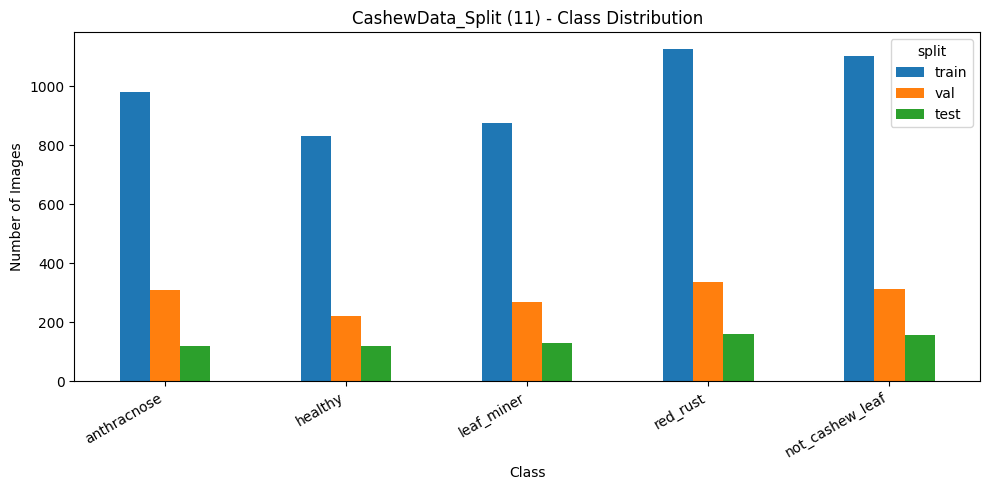

In [9]:
if not VIEW_ONLY:

    # ============================================================
    # 07. DATASET DISTRIBUTION
    # ============================================================

    ax = stats_df[["train", "val", "test"]].plot(
        kind="bar",
        figsize=(10, 5)
    )

    ax.set_title("CashewData_Split (11) - Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Images")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        AGGREGATE_DIR / "class_distribution.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
else:
    print('Cell 11 skipped in VIEW_ONLY')


In [10]:
if not VIEW_ONLY:

    # ============================================================
    # 08. FIXED FILE LISTS + TF.DATA
    # ============================================================

    CLASS_NAMES = EXPECTED_CLASSES
    NUM_CLASSES = len(CLASS_NAMES)
    AUTOTUNE = tf.data.AUTOTUNE


    def split_arrays(split_name):
        df = (
            valid_df[valid_df["split"] == split_name]
            .copy()
            .reset_index(drop=True)
        )

        return (
            df["path"].to_numpy(),
            df["label"].to_numpy(dtype=np.int32),
            df
        )


    train_paths, train_labels, train_meta = split_arrays("train")
    val_paths, val_labels, val_meta = split_arrays("val")
    test_paths, test_labels, test_meta = split_arrays("test")


    def decode_image(path, label):
        image_bytes = tf.io.read_file(path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            [IMG_SIZE, IMG_SIZE],
            method="bilinear"
        )

        return tf.cast(image, tf.float32), label


    def make_dataset(paths, labels, seed, training=False):
        ds = tf.data.Dataset.from_tensor_slices(
            (paths, labels)
        )

        if training:
            ds = ds.shuffle(
                buffer_size=len(paths),
                seed=seed,
                reshuffle_each_iteration=True
            )

        ds = ds.map(
            decode_image,
            num_parallel_calls=AUTOTUNE
        )

        ds = ds.batch(
            BATCH_SIZE,
            drop_remainder=False
        )

        ds = ds.prefetch(AUTOTUNE)

        return ds


    print("Fixed split:")
    print("Train :", len(train_paths))
    print("Val   :", len(val_paths))
    print("Test  :", len(test_paths))

    print("\nClass mapping:")
    for idx, class_name in enumerate(CLASS_NAMES):
        print(f"{idx}: {class_name}")
else:
    print('Cell 12 skipped in VIEW_ONLY')


Fixed split:
Train : 4916
Val   : 1447
Test  : 685

Class mapping:
0: anthracnose
1: healthy
2: leaf_miner
3: red_rust
4: not_cashew_leaf


## REAL HEALTHY TARGET AUGMENTATION ANALYSIS

The frozen source ZIP is audited first. The existing `real_` filename prefix
is the chosen source rule. Only files in `train/healthy/` with that prefix are
eligible. The notebook saves the exact file list and hashes used for this
rule. It checks for repeated Real filenames across splits. Without independent
`leaf_id`/`tree_id` metadata, tree-level leakage cannot be ruled out; this is
a limitation of the experiment, not a passed provenance check.

Generated JPEGs are saved under this run's `augmentation/train/healthy`.
The loader appends them only to Train. A fixed seed produces the same images
for every model seed. This section reports counts, a before/after chart and
original/offline pairs; the next model cell also shows online augmentation
applied to offline samples without changing the online policy.


,Metric,Value
0,Real Healthy Original Train,15
1,Target,30
2,New Augmented Images,15
3,Real Healthy Final Train,30
4,Kaggle Healthy Train,815
5,Total Healthy Train,845
6,Total Train Images,4931
7,Validation Images,1447
8,Test Images,685


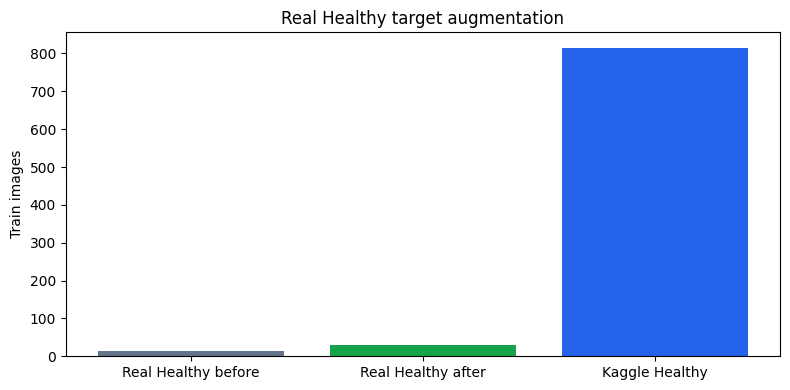

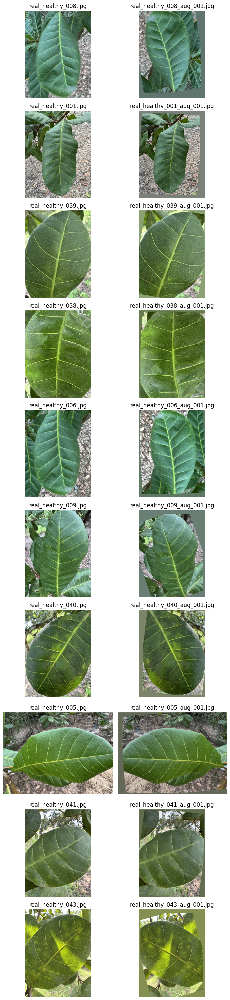

In [11]:
if not VIEW_ONLY:
    import io
    from PIL import ImageOps, ImageEnhance

    if not ENABLE_REAL_HEALTHY_TARGET_AUG:
        raise ValueError("V29 requires ENABLE_REAL_HEALTHY_TARGET_AUG=True")
    source_df = valid_df[["relative_path", "split", "class", "label", "sha256",
                          "path", "is_real_filename"]].copy().rename(columns={
        "split": "split_audit", "class": "class_audit", "sha256": "sha256_audit"})
    source_df["source"] = np.where(source_df.is_real_filename, "real", "kaggle")
    if source_df.relative_path.duplicated().any():
        raise ValueError("Frozen dataset audit contains duplicate relative paths")
    if source_df.groupby("split_audit").is_real_filename.sum().astype(int).to_dict() != EXPECTED_REAL_FILENAME_COUNTS:
        raise ValueError("real_ filename counts differ from the frozen Split (11) audit")
    real_rows = source_df[source_df.source == "real"].copy()
    real_rows["filename_stem"] = real_rows.relative_path.map(
        lambda value: Path(value).stem.casefold())
    stem_split_counts = real_rows.groupby("filename_stem").split_audit.nunique()
    if (stem_split_counts > 1).any():
        raise ValueError("A real_ filename stem occurs in more than one split")
    aug_dir = OUT_DIR / "augmentation"
    image_dir = aug_dir / "train" / "healthy"
    image_dir.mkdir(parents=True, exist_ok=True)
    source_rule_manifest = aug_dir / "source_rule_manifest.csv"
    source_df[["relative_path", "split_audit", "class_audit", "sha256_audit", "source"]].to_csv(
        source_rule_manifest, index=False)
    SOURCE_RULE_MANIFEST_SHA256 = hashlib.sha256(source_rule_manifest.read_bytes()).hexdigest()
    real_healthy = real_rows[(real_rows.split_audit == "train") &
                             (real_rows.class_audit == "healthy")].sort_values("relative_path")
    ORIGINAL_REAL_HEALTHY_COUNT = len(real_healthy)
    if not ORIGINAL_REAL_HEALTHY_COUNT:
        raise ValueError("No real_-prefix Healthy Train images in frozen Split (11)")
    original_train_count = len(train_paths)
    original_val_paths = tuple(map(str, val_paths))
    original_test_paths = tuple(map(str, test_paths))
    additions = max(0, TARGET_REAL_HEALTHY_TRAIN - ORIGINAL_REAL_HEALTHY_COUNT)
    rng = np.random.default_rng(OFFLINE_AUG_SEED)
    candidates = real_healthy.to_dict("records")
    rng.shuffle(candidates)
    augmented_rows = []
    name_counts = {}

    def offline_transform(image, random):
        image = ImageOps.exif_transpose(image).convert("RGB")
        width, height = image.size
        ops = {}
        if random.random() < 0.5:
            image = ImageOps.mirror(image); ops["horizontal_flip"] = True
        if random.random() < 0.3:
            image = ImageOps.flip(image); ops["vertical_flip"] = True
        angle = float(random.uniform(-20, 20))
        if abs(angle) < 3:
            angle = 3 if angle >= 0 else -3
        edge = np.asarray(image)
        border = np.concatenate((edge[0], edge[-1], edge[:, 0], edge[:, -1]))
        fill = tuple(int(x) for x in np.median(border, axis=0))
        image = image.rotate(angle, resample=Image.Resampling.BICUBIC,
                             expand=False, fillcolor=fill)
        ops["rotation_degrees"] = round(angle, 3)
        zoom = float(random.uniform(0.90, 1.10))
        if zoom >= 1:
            crop_w, crop_h = max(2, int(width / zoom)), max(2, int(height / zoom))
            left, top = (width - crop_w) // 2, (height - crop_h) // 2
            image = image.crop((left, top, left + crop_w, top + crop_h)).resize(
                (width, height), Image.Resampling.BICUBIC)
        else:
            small = image.resize((max(2, int(width * zoom)), max(2, int(height * zoom))),
                                 Image.Resampling.BICUBIC)
            canvas = Image.new("RGB", (width, height), fill)
            canvas.paste(small, ((width - small.width) // 2, (height - small.height) // 2))
            image = canvas
        ops["zoom_factor"] = round(zoom, 4)
        dx, dy = int(random.uniform(-.05, .05) * width), int(random.uniform(-.05, .05) * height)
        image = image.transform((width, height), Image.Transform.AFFINE,
                                (1, 0, -dx, 0, 1, -dy),
                                resample=Image.Resampling.BICUBIC, fillcolor=fill)
        ops["translation_pixels"] = [dx, dy]
        brightness = float(random.uniform(.90, 1.10))
        contrast = float(random.uniform(.90, 1.10))
        image = ImageEnhance.Brightness(image).enhance(brightness)
        image = ImageEnhance.Contrast(image).enhance(contrast)
        ops["brightness_factor"] = round(brightness, 4)
        ops["contrast_factor"] = round(contrast, 4)
        return image, ops

    if any(image_dir.iterdir()):
        raise FileExistsError("V29 augmentation directory is nonempty; use a fresh run folder")
    for index in range(additions):
        item = candidates[index % len(candidates)]
        src = Path(item["path"])
        name_counts[src.stem] = name_counts.get(src.stem, 0) + 1
        destination = image_dir / f"{src.stem}_aug_{name_counts[src.stem]:03d}.jpg"
        with Image.open(src) as opened:
            original = ImageOps.exif_transpose(opened).convert("RGB")
        for attempt in range(8):
            generated, ops = offline_transform(original, rng)
            left = np.asarray(original.resize((64, 64)), dtype=np.float32)
            right = np.asarray(generated.resize((64, 64)), dtype=np.float32)
            if float(np.mean(np.abs(left - right))) >= 2.0:
                break
        else:
            raise RuntimeError(f"Could not create a distinct augmentation from {src.name}")
        generated.save(destination, format="JPEG", quality=95, subsampling=0)
        with Image.open(destination) as check:
            check.verify()
        with Image.open(destination) as check:
            if check.format != "JPEG" or check.mode != "RGB" or check.size != original.size:
                raise AssertionError(f"Invalid augmented image: {destination}")
        augmented_rows.append({
            "original_filename": item["relative_path"],
            "augmented_filename": str(destination.relative_to(OUT_DIR).as_posix()),
            "class": "healthy", "source": "real", "split": "train",
            "augmentation_operations": json.dumps(ops, sort_keys=True),
            "augmentation_seed": OFFLINE_AUG_SEED,
            "source_sha256": item["sha256_audit"],
            "augmented_sha256": hashlib.sha256(destination.read_bytes()).hexdigest(),
        })
    manifest_columns = ["original_filename", "augmented_filename", "class", "source", "split",
                        "augmentation_operations", "augmentation_seed",
                        "source_sha256", "augmented_sha256"]
    augmentation_manifest = pd.DataFrame(augmented_rows, columns=manifest_columns)
    manifest_path = aug_dir / "augmentation_manifest.csv"
    augmentation_manifest.to_csv(manifest_path, index=False)
    AUGMENTATION_MANIFEST_SHA256 = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
    aug_paths = [str(OUT_DIR / row["augmented_filename"]) for row in augmented_rows]
    if augmented_rows:
        augmented_meta = pd.DataFrame([{**{column: None for column in train_meta.columns},
            "split": "train", "class": "healthy", "label": EXPECTED_CLASSES.index("healthy"),
            "path": aug_paths[i], "relative_path": row["augmented_filename"],
            "sha256": row["augmented_sha256"], "is_real_filename": True}
            for i, row in enumerate(augmented_rows)])
        train_meta = pd.concat([train_meta, augmented_meta], ignore_index=True)
        train_paths = np.concatenate((train_paths, np.asarray(aug_paths)))
        train_labels = np.concatenate((train_labels,
            np.full(len(aug_paths), EXPECTED_CLASSES.index("healthy"), dtype=np.int32)))
    assert len(augmented_rows) == additions
    assert ORIGINAL_REAL_HEALTHY_COUNT + len(augmented_rows) == max(
        TARGET_REAL_HEALTHY_TRAIN, ORIGINAL_REAL_HEALTHY_COUNT)
    assert len(train_paths) == original_train_count + additions
    assert tuple(map(str, val_paths)) == original_val_paths
    assert tuple(map(str, test_paths)) == original_test_paths
    assert set(aug_paths).isdisjoint(set(map(str, val_paths)) | set(map(str, test_paths)))
    assert set(row["augmented_sha256"] for row in augmented_rows).isdisjoint(
        set(valid_df[valid_df.split.isin(["val", "test"])].sha256))
    assert all(row["class"] == "healthy" and row["split"] == "train" for row in augmented_rows)
    assert len(train_meta[train_meta["class"] != "healthy"]) == len(
        valid_df[(valid_df.split == "train") & (valid_df["class"] != "healthy")])
    TRAIN_FILE_LIST_SHA256 = hashlib.sha256("\n".join(map(str, train_paths)).encode()).hexdigest()
    original_kaggle_healthy = int(((source_df.split_audit == "train") &
        (source_df.class_audit == "healthy") & (source_df.source == "kaggle")).sum())
    counts = {
        "Real Healthy Original Train": ORIGINAL_REAL_HEALTHY_COUNT,
        "Target": TARGET_REAL_HEALTHY_TRAIN,
        "New Augmented Images": additions,
        "Real Healthy Final Train": ORIGINAL_REAL_HEALTHY_COUNT + additions,
        "Kaggle Healthy Train": original_kaggle_healthy,
        "Total Healthy Train": int(sum(train_labels == EXPECTED_CLASSES.index("healthy"))),
        "Total Train Images": len(train_paths),
        "Validation Images": len(val_paths), "Test Images": len(test_paths),
    }
    (aug_dir / "real_healthy_augmentation_summary.json").write_text(
        json.dumps({"counts": counts, "offline_aug_seed": OFFLINE_AUG_SEED,
                    "source_rule": "real_ filename prefix within frozen Split (11)",
                    "source_rule_manifest_sha256": SOURCE_RULE_MANIFEST_SHA256,
                    "augmentation_manifest_sha256": AUGMENTATION_MANIFEST_SHA256,
                    "train_file_list_sha256": TRAIN_FILE_LIST_SHA256,
                    "note": "Generated files are dependent variants. Leaf/tree group integrity cannot be certified without IDs."},
                   indent=2, ensure_ascii=False), encoding="utf-8")
    display(pd.DataFrame(list(counts.items()), columns=["Metric", "Value"]))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(["Real Healthy before", "Real Healthy after", "Kaggle Healthy"],
           [ORIGINAL_REAL_HEALTHY_COUNT, ORIGINAL_REAL_HEALTHY_COUNT + additions,
            original_kaggle_healthy], color=["#64748b", "#16a34a", "#2563eb"])
    ax.set_ylabel("Train images"); ax.set_title("Real Healthy target augmentation")
    fig.tight_layout(); fig.savefig(aug_dir / "real_healthy_counts.png", dpi=180)
    plt.show(); plt.close(fig)
    if augmented_rows:
        show = augmented_rows[:min(10, len(augmented_rows))]
        fig, axes = plt.subplots(len(show), 2, figsize=(7, 3 * len(show)), squeeze=False)
        for i, row in enumerate(show):
            with Image.open(DATASET_PATH / row["original_filename"]) as image:
                axes[i, 0].imshow(ImageOps.exif_transpose(image).convert("RGB"))
            with Image.open(OUT_DIR / row["augmented_filename"]) as image:
                axes[i, 1].imshow(image.convert("RGB"))
            axes[i, 0].set_title(row["original_filename"].split("/")[-1])
            axes[i, 1].set_title(row["augmented_filename"].split("/")[-1])
            for ax in axes[i]: ax.axis("off")
        fig.tight_layout(); fig.savefig(aug_dir / "augmentation_samples.png", dpi=130)
        plt.show(); plt.close(fig)
    else:
        print(f"Already {ORIGINAL_REAL_HEALTHY_COUNT} real_-prefix Healthy Train originals; no augmentation added")
else:
    print("V29 augmentation skipped in VIEW_ONLY")


## Model and smoke checks

Raw RGB pixels (0–255) enter the model. Augmentation happens only during
training. Internal ImageNet normalization matches EXP-009 and is checked
against Keras ResNet50 preprocessing before training. The smoke check uses
one Train batch and one Validation batch; it never reads Test or holdout.


Global seed set to: 42
Global seed set to: 42


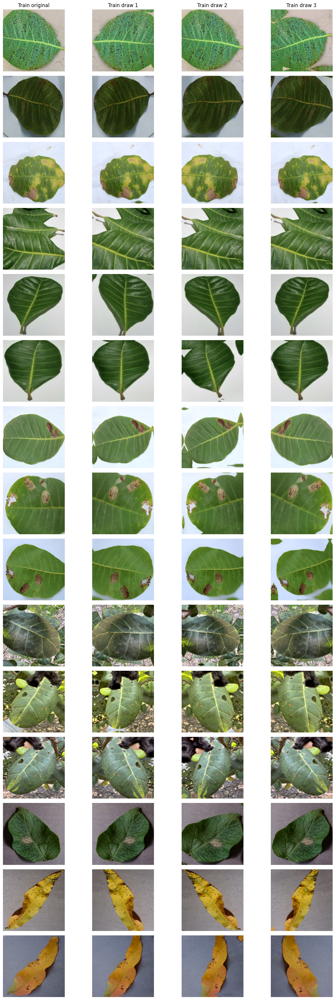

Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload


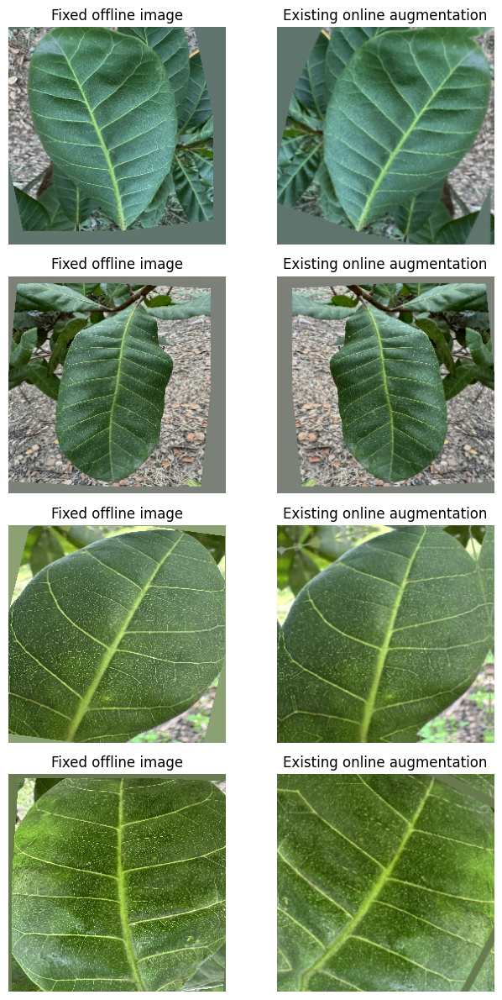

In [12]:
if not VIEW_ONLY:
    # 08. ImageNet backbone, frozen BN, and smoke test
    import tempfile
    from PIL import ImageOps

    AUGMENTATION_CONFIG = {"horizontal_flip": True, "rotation_factor": 0.08,
                           "zoom_factor": 0.10, "contrast_factor": 0.10,
                           "brightness": False}

    def resnet50_preprocessing(inputs):
        x = keras.ops.stack([inputs[..., 2], inputs[..., 1], inputs[..., 0]], axis=-1)
        return x - keras.ops.convert_to_tensor([103.939, 116.779, 123.68], dtype="float32")

    def build_transfer_model(seed, weights="imagenet"):
        set_global_seed(seed)
        inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
        augmented = keras.Sequential([
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(0.08, seed=seed),
            layers.RandomZoom(0.10, seed=seed),
            layers.RandomContrast(0.10, seed=seed),
        ], name=f"train_only_augmentation_seed_{seed}")(inputs)
        x = resnet50_preprocessing(augmented)
        backbone = keras.applications.ResNet50(include_top=False, weights=weights,
                                                   input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
        backbone.trainable = False
        features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
        x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                               name="disease_output")(x)
        return keras.Model(inputs, outputs, name=f"ResNet50_Transfer_seed_{seed}"), backbone

    def set_backbone_stage(backbone, stage):
        if stage == "stage1":
            backbone.trainable = False
        elif stage == "stage2":
            backbone.trainable = True
            for layer in backbone.layers:
                layer.trainable = (layer.name.startswith("conv5_block3_") and
                                   not isinstance(layer, layers.BatchNormalization))
            if not any(layer.trainable and layer.weights for layer in backbone.layers):
                raise RuntimeError("No weighted conv5_block3_* layer was unfrozen")
            if any(layer.trainable for layer in backbone.layers
                   if isinstance(layer, layers.BatchNormalization)):
                raise RuntimeError("A backbone BatchNorm layer is trainable")
        else:
            raise ValueError(stage)
        return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

    def compile_stage(model, lr):
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                      weight_decay=WEIGHT_DECAY),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

    def save_json(path, value):
        path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

    def file_sha256(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()

    if RUN_PIPELINE_SMOKE:
        # enable_op_determinism() requires a global seed before any random op.
        set_global_seed(SEEDS[0])
        parity_input = tf.random.uniform((2, IMG_SIZE, IMG_SIZE, 3), 0, 255, dtype=tf.float32)
        parity_model = keras.Model((p := keras.Input((IMG_SIZE, IMG_SIZE, 3))),
                                   resnet50_preprocessing(p))
        parity_error = float(tf.reduce_max(tf.abs(
            parity_model(parity_input) - keras.applications.resnet50.preprocess_input(parity_input)
        )).numpy())
        if parity_error >= 1e-5:
            raise AssertionError(f"ResNet50 preprocessing parity failed: {parity_error}")
        smoke_train = next(iter(make_dataset(train_paths, train_labels, SEEDS[0], training=True)))
        smoke_val = next(iter(make_dataset(val_paths, val_labels, SEEDS[0], training=False)))
        model, backbone = build_transfer_model(SEEDS[0], weights="imagenet")
        augmentation = model.get_layer(f"train_only_augmentation_seed_{SEEDS[0]}")
        qa_paths = []
        for class_name in CLASS_NAMES:
            subset = train_meta[train_meta["class"] == class_name].head(3)
            if len(subset) != 3:
                raise AssertionError(f"Need 3 Train images for {class_name}")
            qa_paths += subset["path"].tolist()
        qa_input = tf.stack([decode_image(tf.constant(str(path)), tf.constant(0))[0]
                             for path in qa_paths])
        original = qa_input.numpy()
        for repeat in range(2):
            if not np.allclose(augmentation(qa_input, training=False).numpy(), original, atol=1e-5):
                raise AssertionError(f"Augmentation changed inference image (pass {repeat})")
        draws = [augmentation(qa_input, training=True).numpy() for _ in range(3)]
        if not all(np.isfinite(d).all() and d.min() >= -1e-4 and d.max() <= 255.0001 for d in draws):
            raise AssertionError("Augmentation produced nonfinite/out-of-range pixels")
        if not any(np.mean(np.abs(d - original)) > .1 for d in draws):
            raise AssertionError("Train augmentation inactive")
        if not any(np.mean(np.abs(draws[i] - draws[j])) > .1 for i in range(3) for j in range(i+1, 3)):
            raise AssertionError("Train augmentation not stochastic")
        qa_dir = OUT_DIR / "figures" / "augmentation"
        qa_dir.mkdir(parents=True, exist_ok=True)
        fig, axes = plt.subplots(15, 4, figsize=(13, 34), facecolor="white")
        for row, path in enumerate(qa_paths):
            for col, pixels in enumerate([original] + draws):
                axes[row, col].imshow(np.clip(pixels[row], 0, 255).astype(np.uint8))
                axes[row, col].axis("off")
                if row == 0: axes[row, col].set_title("Train original" if col == 0 else f"Train draw {col}")
                if col == 0: axes[row, col].set_ylabel(f"{CLASS_NAMES[row//3]} / {row%3+1}")
        fig.tight_layout()
        qa_path = qa_dir / "augmentation_qa_5classes.png"
        fig.savefig(qa_path, dpi=130, bbox_inches="tight")
        display(fig); plt.close(fig)
        initial_backbone = [w.numpy().copy() for w in backbone.weights[:2]]
        stage1_params = set_backbone_stage(backbone, "stage1")
        if stage1_params != 0 or not model.trainable_weights:
            raise AssertionError("Stage 1 trainability is wrong")
        compile_stage(model, STAGE1_LR)
        model.train_on_batch(*smoke_train)
        if any(not np.array_equal(a, w.numpy()) for a, w in zip(initial_backbone, backbone.weights[:2])):
            raise AssertionError("Frozen backbone changed in Stage 1")
        stage1_prob = model(smoke_val[0][:2], training=False).numpy()
        if stage1_prob.shape != (2, NUM_CLASSES) or not np.isfinite(stage1_prob).all():
            raise AssertionError("Invalid model output")
        if not np.allclose(stage1_prob,
                           model(smoke_val[0][:2], training=False).numpy(), atol=1e-6):
            raise AssertionError("Validation/inference path is stochastic")
        if not np.allclose(stage1_prob.sum(axis=1), 1.0, atol=1e-5):
            raise AssertionError("Softmax probabilities do not sum to one")
        bn_layers = [layer for layer in backbone.layers if isinstance(layer, layers.BatchNormalization)]
        if len(bn_layers) != 53: raise AssertionError("Expected 53 BatchNorm layers")
        bn_means = [layer.moving_mean.numpy().copy() for layer in bn_layers]
        stage2_params = set_backbone_stage(backbone, "stage2")
        if stage2_params <= 0:
            raise AssertionError("Stage 2 trainable parameter count is implausible")
        old_optimizer = model.optimizer
        compile_stage(model, STAGE2_LR)
        if model.optimizer is old_optimizer:
            raise AssertionError("Stage 2 reused the Stage 1 optimizer")
        model.train_on_batch(*smoke_train)
        if any(not np.array_equal(before, layer.moving_mean.numpy())
               for before, layer in zip(bn_means, bn_layers)):
            raise AssertionError("Backbone BatchNorm moving means changed")
        with tempfile.TemporaryDirectory() as temporary:
            weights_path = Path(temporary) / "smoke.weights.h5"
            model_path = Path(temporary) / "smoke.keras"
            expected = model(smoke_val[0][:2], training=False).numpy()
            model.save_weights(weights_path)
            model.save(model_path)
            head_bias = model.layers[-1].bias
            head_bias.assign_add(tf.one_hot(0, NUM_CLASSES, on_value=20.0,
                                            off_value=0.0, dtype=head_bias.dtype))
            if np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
                raise AssertionError("Smoke mutation did not change predictions")
            model.load_weights(weights_path)
            if not np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
                raise AssertionError("Saved weights did not restore predictions")
            restored = keras.models.load_model(model_path, compile=False)
            if not np.allclose(expected, restored(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
                raise AssertionError("Saved .keras model changed predictions")
        save_json(OUT_DIR / "pipeline_smoke.json", {
            "status": "PASS", "preprocess_max_abs_error": parity_error,
            "stage1_backbone_trainable_params": stage1_params,
            "stage2_backbone_trainable_params": stage2_params,
            "backbone_batchnorm_layers": len(bn_layers),
            "weights_and_model_reload": "PASS", "imagenet_initialization": "PASS",
            "inference_augmentation_identity": "PASS", "train_augmentation_stochastic": "PASS",
        })
        print("Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload")
        del model, backbone, restored
        keras.backend.clear_session(); gc.collect()
    else:
        print("Pipeline smoke NOT_EXECUTED")
    if aug_paths:
        preview_layers = keras.Sequential([
            layers.RandomFlip("horizontal", seed=SEEDS[0]),
            layers.RandomRotation(0.08, seed=SEEDS[0]),
            layers.RandomZoom(0.10, seed=SEEDS[0]),
            layers.RandomContrast(0.10, seed=SEEDS[0]),
        ])
        preview_paths = aug_paths[:min(4, len(aug_paths))]
        offline_batch = tf.stack([decode_image(tf.constant(p), tf.constant(0))[0]
                                  for p in preview_paths])
        online_batch = preview_layers(offline_batch, training=True).numpy()
        fig, axes = plt.subplots(len(preview_paths), 2, figsize=(7, 3 * len(preview_paths)),
                                 squeeze=False)
        for i, p in enumerate(preview_paths):
            axes[i, 0].imshow(np.clip(offline_batch[i].numpy() / 255, 0, 1))
            axes[i, 1].imshow(np.clip(online_batch[i] / 255, 0, 1))
            axes[i, 0].set_title("Fixed offline image")
            axes[i, 1].set_title("Existing online augmentation")
            for ax in axes[i]: ax.axis("off")
        fig.tight_layout()
        fig.savefig(OUT_DIR / "augmentation" / "offline_plus_online_samples.png", dpi=140)
        plt.show(); plt.close(fig)
else:
    print('Model smoke skipped in VIEW_ONLY')


## Freeze the recipe, then train both stages

The configuration and dataset fingerprint are written before fitting. Each
seed has separate Stage 1 and Stage 2 histories and checkpoints. Stage 2
starts from the best Stage 1 weights, uses a fresh optimizer, and keeps
BatchNorm frozen. The selected seed checkpoint comes from Validation only.


In [13]:
if VIEW_ONLY:
    config_path = OUT_DIR / "experiment_config.json"
    experiment_config = json.loads(config_path.read_text(encoding="utf-8"))
    CONFIG_SHA256 = hashlib.sha256(config_path.read_bytes()).hexdigest()
    DATASET_ZIP_SHA256 = experiment_config["dataset"]["archive_sha256"]
    DATASET_MANIFEST_SHA256 = experiment_config["dataset"]["manifest_sha256"]
    CLASS_NAMES = experiment_config["dataset"]["class_names"]
    NUM_CLASSES = len(CLASS_NAMES)
    if experiment_config.get("code_revision_sha256") != CODE_REVISION_SHA256:
        raise ValueError("VIEW_ONLY notebook revision differs from saved EXP-029 recipe")
    if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256 or (EXPECTED_MANIFEST_SHA256 is not None and DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256):
        raise ValueError("Saved dataset fingerprint differs")
else:
    # 09. Immutable experiment recipe
    experiment_config = {
        "experiment_id": EXPERIMENT_ID, "notebook_version": NOTEBOOK_VERSION,
        "parent_experiment_id": "EXP-RESNET50-TRANSFER-5SEEDS-028",
        "code_revision_sha256": CODE_REVISION_SHA256,
        "baseline_source": "Unexecuted ResNet50 V28 256x256 recipe; offline Real Healthy Train augmentation only",
        "comparison_scope": "V28 recipe on frozen Split (11); Real Healthy Train target 30",
        "dataset": {"name": DATASET_VERSION, "archive": DATASET_ARCHIVE_NAME,
                    "archive_sha256": DATASET_ZIP_SHA256,
                    "manifest_sha256": DATASET_MANIFEST_SHA256,
                    "counts": EXPECTED_TOTALS, "class_names": EXPECTED_CLASSES,
                    "real_filename_counts": EXPECTED_REAL_FILENAME_COUNTS},
        "seeds": SEEDS, "input": f"raw RGB float32 0..255, bilinear resize {IMG_SIZE}x{IMG_SIZE}",
        "offline_target_augmentation": {
            "enabled": ENABLE_REAL_HEALTHY_TARGET_AUG,
            "target_real_healthy_train": TARGET_REAL_HEALTHY_TRAIN,
            "seed": OFFLINE_AUG_SEED,
            "source_rule_manifest_sha256": SOURCE_RULE_MANIFEST_SHA256,
            "augmentation_manifest_sha256": AUGMENTATION_MANIFEST_SHA256,
            "original_real_healthy_train": ORIGINAL_REAL_HEALTHY_COUNT,
            "generated_images": len(augmented_rows),
            "effective_train_images": len(train_paths),
            "online_augmentation": "unchanged from V28"},
        "model": {"backbone": "ResNet50", "weights": "imagenet",
                  "include_top": False, "pooling": "avg", "head_dropout": HEAD_DROPOUT,
                  "preprocessing": "inside model: RGB to BGR, subtract Caffe BGR means; no /255",
                  "augmentation": AUGMENTATION_CONFIG,
                  "backbone_call": "backbone(x, training=False)"},
        "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
        "loss": "SparseCategoricalCrossentropy",
        "stage1": {"lr": STAGE1_LR, "max_epochs": STAGE1_EPOCHS,
                   "early_patience": STAGE1_EARLY_PATIENCE,
                   "reduce_patience": STAGE1_REDUCE_PATIENCE, "min_lr": STAGE1_MIN_LR,
                   "trainable_backbone": "none"},
        "stage2": {"lr": STAGE2_LR, "max_epochs": STAGE2_EPOCHS,
                   "early_patience": STAGE2_EARLY_PATIENCE,
                   "reduce_patience": STAGE2_REDUCE_PATIENCE, "min_lr": STAGE2_MIN_LR,
                   "trainable_backbone": "conv5_block3_* non-BatchNorm only"},
        "selection_rule": "val_loss tolerance 1e-6; higher macro-F1; Stage 1 on tie",
        "deployment_rule": "val_loss tolerance 1e-6; higher macro-F1; lower seed on tie",
        "test_protocol": "enabled Final Test after five-seed Validation lock",
        "holdout_protocol": "historical exposed 120-image four-true-class Holdout (5); Validation lock precedes evaluation",
    }
    config_path = OUT_DIR / "experiment_config.json"
    if RUN_FULL_TRAINING:
        smoke_path = OUT_DIR / "pipeline_smoke.json"
        if not smoke_path.is_file() or json.loads(smoke_path.read_text(
                encoding="utf-8")).get("status") != "PASS":
            raise RuntimeError("Pipeline smoke must PASS before five-seed training")
    if config_path.exists():
        if json.loads(config_path.read_text(encoding="utf-8")) != experiment_config:
            raise ValueError("Existing EXP-029 recipe differs. Use a new experiment ID for changes.")
    else:
        save_json(config_path, experiment_config)
    CONFIG_SHA256 = file_sha256(config_path)
    print("Frozen recipe SHA256:", CONFIG_SHA256)
    save_json(OUT_DIR / "execution_status.json", {
        "experiment_id": EXPERIMENT_ID, "training": "PENDING", "validation": "PENDING",
        "test": "PENDING", "real_holdout": "PENDING",
        "smoke": "PASS" if RUN_PIPELINE_SMOKE else "NOT_EXECUTED"})

if not VIEW_ONLY:
    save_json(ENV_DIR / "runtime.json", {
        "python": sys.version, "tensorflow": tf.__version__,
        "keras": getattr(keras, "__version__", "tf.keras"),
        "platform": platform.platform(), "gpu": [str(g) for g in gpus],
        "cuda_build": str(tf.sysconfig.get_build_info().get("cuda_version", "unknown")),
        "seeds": SEEDS, "code_revision_sha256": CODE_REVISION_SHA256,
        "code_revision_method": "SHA256 of cells 14, 16, 19, 22, 24, 28, 35, 36, 39 before source embedding"})


Frozen recipe SHA256: ab858d00e48587edbcdea828a8cd7103941cd4d8e9df79c23b870b7a5b2746f0


In [14]:
# 10–14. Two-stage five-seed training and Validation-only selection
class EpochAudit(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.current_lr = None
    def on_epoch_begin(self, epoch, logs=None):
        self.current_lr = float(self.model.optimizer.learning_rate.numpy())
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({"epoch": epoch + 1, "accuracy": float(logs["accuracy"]),
                          "loss": float(logs["loss"]),
                          "val_accuracy": float(logs["val_accuracy"]),
                          "val_loss": float(logs["val_loss"]),
                          "learning_rate": self.current_lr})

def stage_callbacks(stage_dir, early_patience, reduce_patience, min_lr):
    audit = EpochAudit()
    checkpoint = stage_dir / "best.weights.h5"
    callbacks = [
        audit,
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=early_patience,
                                      restore_best_weights=False, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=LR_REDUCTION_FACTOR,
                                          patience=reduce_patience, min_lr=min_lr, verbose=1),
        keras.callbacks.CSVLogger(str(stage_dir / "training_log.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]
    return audit, callbacks, checkpoint

def evaluate_candidate(model, val_ds, stage_dir, stage, audit, elapsed, trainable_params):
    history = pd.DataFrame(audit.rows)
    if history.empty or not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError(f"Invalid {stage} history")
    history.to_csv(stage_dir / "history.csv", index=False)
    best = history.sort_values(["val_loss", "epoch"], ascending=[True, True]).iloc[0]
    checkpoint = stage_dir / "best.weights.h5"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    model.load_weights(checkpoint)
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    predicted = probabilities.argmax(axis=1)
    candidate = {
        "stage": stage, "best_epoch": int(best["epoch"]),
        "actual_epochs": len(history), "fit_seconds": float(elapsed),
        "val_loss": float(val_loss), "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(f1_score(val_labels, predicted, labels=np.arange(NUM_CLASSES),
                                        average="macro", zero_division=0)),
        "checkpoint_path": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
        "checkpoint_size_mb": checkpoint.stat().st_size / (1024 ** 2),
        "backbone_trainable_params": trainable_params,
        "learning_rate_first": float(history.iloc[0]["learning_rate"]),
        "learning_rate_last": float(history.iloc[-1]["learning_rate"]),
    }
    if not np.isclose(candidate["val_loss"], float(best["val_loss"]), atol=1e-5):
        raise RuntimeError(f"Reloaded {stage} checkpoint differs from best val_loss epoch")
    save_json(stage_dir / "summary.json", candidate)
    return candidate

def save_selected_validation(seed, model, val_ds, seed_dir, selected):
    output = seed_dir / "validation"
    output.mkdir(exist_ok=True)
    _ = model.predict(val_ds.take(1), verbose=0)  # Warm up model tracing.
    prediction_started = time.perf_counter()
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    prediction_seconds = time.perf_counter() - prediction_started
    y_true = np.asarray(val_labels, dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    if probabilities.shape != (len(y_true), NUM_CLASSES):
        raise ValueError("Validation predictions are not aligned to the fixed file list")
    metrics = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"],
        "val_loss": selected["val_loss"],
        "val_accuracy": float(accuracy_score(y_true, y_pred)),
        "val_macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "prediction_seconds_including_input_pipeline": float(prediction_seconds),
        "inference_time_ms_per_image": float(1000 * prediction_seconds / len(y_true)),
        "anthracnose_recall": float(recall_score(y_true == CLASS_NAMES.index("anthracnose"),
                                                  y_pred == CLASS_NAMES.index("anthracnose"), zero_division=0)),
        "leaf_miner_recall": float(recall_score(y_true == CLASS_NAMES.index("leaf_miner"),
                                                 y_pred == CLASS_NAMES.index("leaf_miner"), zero_division=0)),
    }
    disease_ids = [CLASS_NAMES.index(name) for name in ("anthracnose", "leaf_miner", "red_rust")]
    disease_mask = np.isin(y_true, disease_ids)
    false_healthy_count = int(np.sum(disease_mask & (y_pred == CLASS_NAMES.index("healthy"))))
    metrics.update(false_healthy_count=false_healthy_count,
                   disease_count=int(disease_mask.sum()),
                   false_healthy_rate=float(false_healthy_count / disease_mask.sum()))
    healthy_mask = y_true == CLASS_NAMES.index("healthy")
    diseased_prediction = np.isin(y_pred, disease_ids)
    metrics.update(
        healthy_to_diseased_count=int(np.sum(healthy_mask & diseased_prediction)),
        healthy_count=int(healthy_mask.sum()),
        healthy_to_diseased_rate=float(np.sum(healthy_mask & diseased_prediction) / healthy_mask.sum()))
    if metrics["healthy_count"] != EXPECTED_COUNTS["healthy"]["val"]:
        raise ValueError("Healthy Validation denominator changed")
    save_json(output / "metrics.json", metrics)
    pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                       target_names=CLASS_NAMES, output_dict=True,
                                       zero_division=0)).T.to_csv(output / "classification_report.csv")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES), normalize="true")
    for matrix, suffix in ((cm, ""), (cm_norm, "_normalized")):
        pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            output / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if suffix else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for column in range(NUM_CLASSES):
                ax.text(column, row, f"{matrix[row, column]:.2f}" if suffix else str(int(matrix[row, column])),
                        ha="center", va="center", color="black")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        fig.tight_layout(); fig.savefig(output / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    predictions = pd.DataFrame({
        "filename": val_meta["path"], "is_real_filename": val_meta["is_real_filename"],
        "true_label": [CLASS_NAMES[i] for i in y_true],
        "predicted_label": [CLASS_NAMES[i] for i in y_pred],
        "confidence": probabilities.max(axis=1), "correct": y_true == y_pred,
    })
    for index, name in enumerate(CLASS_NAMES):
        predictions[f"prob_{name}"] = probabilities[:, index]
    predictions.to_csv(output / "predictions.csv", index=False)
    predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
    return metrics

training_rows, validation_rows = [], []
def choose_stage(stage1, stage2, tolerance=1e-6):
    delta = stage1["val_loss"] - stage2["val_loss"]
    if abs(delta) > tolerance:
        return stage1 if delta < 0 else stage2
    if abs(stage1["val_macro_f1"] - stage2["val_macro_f1"]) > 1e-12:
        return max((stage1, stage2), key=lambda row: row["val_macro_f1"])
    return stage1

for run_index, seed in enumerate(SEEDS if RUN_FULL_TRAINING else [], start=1):
    if hashlib.sha256("\n".join(map(str, train_paths)).encode()).hexdigest() != TRAIN_FILE_LIST_SHA256:
        raise RuntimeError("V29 fixed augmented Train file list changed between seeds")
    seed_dir = OUT_DIR / f"seed_{seed}"
    stage1_dir, stage2_dir = seed_dir / "stage1", seed_dir / "stage2"
    selected_path = seed_dir / "best.weights.h5"
    summary_path = seed_dir / "training_summary.json"
    validation_path = seed_dir / "validation" / "metrics.json"
    if seed_dir.exists() and any(seed_dir.rglob("*")):
        raise FileExistsError(f"Seed output already exists: {seed_dir}. Use a new experiment ID for a fresh run")
    for directory in (stage1_dir, stage2_dir):
        directory.mkdir(parents=True)
    print(f"SEED {run_index}/{len(SEEDS)}: {seed}")
    keras.backend.clear_session(); gc.collect(); set_global_seed(seed)
    train_ds = make_dataset(train_paths, train_labels, seed, training=True)
    val_ds = make_dataset(val_paths, val_labels, seed, training=False)
    model, backbone = build_transfer_model(seed, weights="imagenet")

    stage1_params = set_backbone_stage(backbone, "stage1")
    compile_stage(model, STAGE1_LR)
    audit1, callbacks1, _ = stage_callbacks(stage1_dir, STAGE1_EARLY_PATIENCE,
                                            STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE1_EPOCHS,
              callbacks=callbacks1, verbose=1)
    stage1_seconds = time.perf_counter() - started
    stage1 = evaluate_candidate(model, val_ds, stage1_dir, "stage1", audit1,
                                stage1_seconds, stage1_params)

    # evaluate_candidate restored Stage 1 best. Stage 2 starts from these exact weights.
    stage2_params = set_backbone_stage(backbone, "stage2")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 must have a new optimizer")
    audit2, callbacks2, _ = stage_callbacks(stage2_dir, STAGE2_EARLY_PATIENCE,
                                            STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE2_EPOCHS,
              callbacks=callbacks2, verbose=1)
    stage2_seconds = time.perf_counter() - started
    stage2 = evaluate_candidate(model, val_ds, stage2_dir, "stage2", audit2,
                                stage2_seconds, stage2_params)

    selected = choose_stage(stage1, stage2)
    set_backbone_stage(backbone, selected["stage"])
    source_checkpoint = stage1_dir if selected["stage"] == "stage1" else stage2_dir
    model.load_weights(source_checkpoint / "best.weights.h5")
    selected_reloaded_loss = float(model.evaluate(val_ds, verbose=0)[0])
    if not np.isclose(selected_reloaded_loss, selected["val_loss"], atol=1e-5):
        raise RuntimeError("Selected stage checkpoint failed reload parity")
    shutil.copyfile(source_checkpoint / "best.weights.h5", selected_path)
    stage_selection = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"], "selection_metric": "val_loss",
        "val_loss": selected["val_loss"], "val_macro_f1": selected["val_macro_f1"],
        "tie_break": "higher val_macro_f1, then Stage 1",
        "checkpoint_sha256": file_sha256(selected_path),
        "model_params": int(model.count_params()),
        "stage_candidates": {"stage1": stage1, "stage2": stage2},
    }
    save_json(seed_dir / "stage_selection.json", stage_selection)
    validation = save_selected_validation(seed, model, val_ds, seed_dir, selected)
    summary = {
        "seed": seed, "selected_stage": selected["stage"],
        "stage1_epochs": stage1["actual_epochs"], "stage2_epochs": stage2["actual_epochs"],
        "stage1_training_seconds": stage1_seconds, "stage2_training_seconds": stage2_seconds,
        "training_time_seconds": stage1_seconds + stage2_seconds,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "total_parameters": int(model.count_params()),
        "selected_checkpoint_sha256": stage_selection["checkpoint_sha256"],
        "selected_checkpoint_size_mb": selected_path.stat().st_size / (1024 ** 2),
    }
    save_json(summary_path, summary)
    training_rows.append(summary); validation_rows.append(validation)
    del model, backbone, train_ds, val_ds
    keras.backend.clear_session(); gc.collect()

if RUN_FULL_TRAINING:
    training_summary_df = pd.DataFrame(training_rows)
    validation_results_df = pd.DataFrame(validation_rows)
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise RuntimeError("All five seeds must complete before aggregation")
    training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
    validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
elif VIEW_ONLY or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
    validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise ValueError("Saved five-seed order does not match the protocol")

def choose_deployment_seed(rows, tolerance=1e-6):
    candidates = rows.to_dict("records")
    lowest = min(float(row["val_loss"]) for row in candidates)
    near = [row for row in candidates if float(row["val_loss"]) <= lowest + tolerance]
    return int(sorted(near, key=lambda row: (-float(row["val_macro_f1"]), int(row["seed"])))[0]["seed"])

if RUN_FULL_TRAINING or VIEW_ONLY or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    deployment_seed = choose_deployment_seed(validation_results_df)
    selection_lock = {
        "experiment_id": EXPERIMENT_ID, "config_sha256": CONFIG_SHA256,
        "dataset_sha256": DATASET_ZIP_SHA256,
        "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
        "class_names": CLASS_NAMES, "seeds": SEEDS,
        "selection_rule": experiment_config["selection_rule"],
        "deployment_rule": experiment_config["deployment_rule"],
        "deployment_seed": deployment_seed,
        "validation_sha256": file_sha256(AGGREGATE_DIR / "validation_results_5seeds.csv"),
        "selected_checkpoint_sha256": {
            str(seed): file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5") for seed in SEEDS
        },
    }
    lock_path = OUT_DIR / "validation_selection_lock.json"
    if lock_path.exists():
        previous_lock = json.loads(lock_path.read_text(encoding="utf-8"))
        selection_lock["locked_at"] = previous_lock.get("locked_at")
        if previous_lock != selection_lock:
            raise ValueError("Validation lock changed; do not run Test or holdout")
    else:
        selection_lock["locked_at"] = datetime.now().astimezone().isoformat()
        save_json(lock_path, selection_lock)
    print("Validation-only deployment seed:", deployment_seed)
else:
    print('Training/Validation PENDING')


SEED 1/5: 42
Global seed set to: 42
Global seed set to: 42
Epoch 1/18
307/309 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3849 - loss: 1.5665
Epoch 1: val_loss improved from None to 0.61119, saving model to /content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029/seed_42/stage1/best.weights.h5

Epoch 1: finished saving model to /content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029/seed_42/stage1/best.weights.h5
309/309 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.5145 - loss: 1.2370 - val_accuracy: 0.8293 - val_loss: 0.6112 - learning_rate: 1.0000e-04
Epoch 2/18
306/309 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7447 - loss: 0.7259
Epoch 2: val_loss improved from 0.61119 to 0.37504, saving model to /content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029/seed_42/stage1/best.weights.h5

Epoch 2: finished saving model to /content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029/seed_42/stage1/best.weights

In [15]:
if RUN_FULL_TRAINING:
    # 15–17. Validation tables, real_ subgroup, and five-seed panels
    summary_columns = ["val_accuracy", "val_macro_precision", "val_macro_recall",
                       "val_macro_f1", "val_balanced_accuracy", "anthracnose_recall",
                       "leaf_miner_recall", "false_healthy_rate"]
    summary_rows = []
    for metric in summary_columns:
        values = validation_results_df[metric].astype(float)
        summary_rows.append({"metric": metric, "mean": values.mean(),
                             "std": values.std(ddof=1),
                             "report": f"{100*values.mean():.2f} ± {100*values.std(ddof=1):.2f}%"})
    inference_ms = validation_results_df["inference_time_ms_per_image"].astype(float)
    summary_rows.append({"metric": "inference_time_ms_per_image",
                         "mean": inference_ms.mean(), "std": inference_ms.std(ddof=1),
                         "report": f"{inference_ms.mean():.2f} ± {inference_ms.std(ddof=1):.2f} ms"})
    pd.DataFrame(summary_rows).to_csv(AGGREGATE_DIR / "validation_mean_std_summary.csv", index=False)
    training_time_columns = ["stage1_training_seconds", "stage2_training_seconds", "training_time_seconds"]
    pd.DataFrame([{"metric": column,
                   "mean_seconds": training_summary_df[column].mean(),
                   "std_seconds": training_summary_df[column].std(ddof=1),
                   "total_seconds": training_summary_df[column].sum()}
                  for column in training_time_columns]).to_csv(
        AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)

    real_rows, per_class_rows = [], []
    for seed in SEEDS:
        val_dir = OUT_DIR / f"seed_{seed}" / "validation"
        predictions = pd.read_csv(val_dir / "predictions.csv")
        if len(predictions) != EXPECTED_TOTALS["val"]:
            raise RuntimeError(f"Seed {seed} Validation rows changed")
        for group, group_df in (("real_filename", predictions[predictions["is_real_filename"]]),
                                ("other_filename", predictions[~predictions["is_real_filename"]]),
                                ("real_healthy_filename", predictions[predictions["is_real_filename"] &
                                    (predictions["true_label"] == "healthy")])):
            real_rows.append({"seed": seed, "group": group, "correct": int(group_df["correct"].sum()),
                              "total": len(group_df),
                              "accuracy": float(group_df["correct"].mean())})
        real_healthy_row = real_rows[-1]
        if real_healthy_row["total"] != int(((valid_df["split"] == "val") &
            (valid_df["class"] == "healthy") & valid_df["is_real_filename"]).sum()):
            raise ValueError("real_ Healthy Validation count changed")
        report = pd.read_csv(val_dir / "classification_report.csv", index_col=0)
        for class_name in CLASS_NAMES:
            per_class_rows.append({"seed": seed, "class": class_name,
                                   "precision": report.loc[class_name, "precision"],
                                   "recall": report.loc[class_name, "recall"],
                                   "f1": report.loc[class_name, "f1-score"],
                                   "support": report.loc[class_name, "support"]})
    real_validation_df = pd.DataFrame(real_rows)
    for seed in SEEDS:
        row = real_validation_df[(real_validation_df["seed"] == seed) &
                                 (real_validation_df["group"] == "real_filename")].iloc[0]
        if int(row["total"]) != EXPECTED_REAL_FILENAME_COUNTS["val"]:
            raise ValueError("The real_ Validation filename count changed")
    real_validation_df.to_csv(AGGREGATE_DIR / "real_validation_by_seed.csv", index=False)
    pd.DataFrame(per_class_rows).to_csv(AGGREGATE_DIR / "per_class_validation_by_seed.csv", index=False)
    pd.DataFrame(per_class_rows).groupby("class")[["precision", "recall", "f1"]].agg(
        ["mean", "std"]).to_csv(AGGREGATE_DIR / "per_class_validation_mean_std.csv")

    histories = {}
    for seed in SEEDS:
        histories[seed] = (
            pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage1" / "history.csv"),
            pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage2" / "history.csv"),
        )
    fig, axes = plt.subplots(2, len(SEEDS), figsize=(28, 10), sharey="row")
    for column, seed in enumerate(SEEDS):
        stage1, stage2 = histories[seed]
        boundary = len(stage1)
        for row, metric in enumerate(("accuracy", "loss")):
            ax = axes[row, column]
            for stage_df, offset, stage_name in ((stage1, 0, "Stage 1"), (stage2, boundary, "Stage 2")):
                epoch = stage_df["epoch"] + offset
                ax.plot(epoch, stage_df[metric], color="#2563eb", alpha=0.75,
                        label=f"{stage_name} Train" if row == 0 else None)
                ax.plot(epoch, stage_df[f"val_{metric}"], color="#ea580c", alpha=0.9,
                        label=f"{stage_name} Validation" if row == 0 else None)
                lr = stage_df["learning_rate"].to_numpy()
                reduced = np.flatnonzero(lr[1:] < lr[:-1]) + 1
                for index in reduced:
                    ax.axvline(float(epoch.iloc[index]), color="#16a34a", alpha=0.35, linestyle=":")
            ax.axvline(boundary + 0.5, color="black", linestyle="--", alpha=0.8)
            ax.set_xlabel("Combined epoch"); ax.grid(alpha=0.25)
            if column == 0:
                ax.set_ylabel(metric.title())
        axes[0, column].set_title(f"Seed {seed}")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Stage boundary: dashed; learning-rate reductions: dotted green")
    fig.tight_layout()
    fig.savefig(PANEL_DIR / "accuracy_loss_curves_5seeds.png", dpi=190, bbox_inches="tight")
    plt.close(fig)

    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"validation_confusion_matrices_5seeds{suffix}.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    print("Validation summary:")
    display(pd.DataFrame(summary_rows))
    print("Validation real_ filename subgroup:")
    display(real_validation_df)
else:
    print('Validation figures PENDING')


Validation summary:


,metric,mean,std,report
0,val_accuracy,0.956462,0.003848,95.65 ± 0.38%
1,val_macro_precision,0.954211,0.004041,95.42 ± 0.40%
2,val_macro_recall,0.955479,0.003783,95.55 ± 0.38%
3,val_macro_f1,0.954753,0.003918,95.48 ± 0.39%
4,val_balanced_accuracy,0.955479,0.003783,95.55 ± 0.38%
5,anthracnose_recall,0.915858,0.007590,91.59 ± 0.76%
6,leaf_miner_recall,0.934082,0.007766,93.41 ± 0.78%
7,false_healthy_rate,0.013831,0.001252,1.38 ± 0.13%
8,inference_time_ms_per_image,0.471936,0.006520,0.47 ± 0.01 ms


Validation real_ filename subgroup:


,seed,group,correct,total,accuracy
0,42,real_filename,40,54,0.740741
1,42,other_filename,1343,1393,0.964106
2,42,real_healthy_filename,3,7,0.428571
3,123,real_filename,43,54,0.796296
4,123,other_filename,1348,1393,0.967696
5,123,real_healthy_filename,5,7,0.714286
6,2026,real_filename,43,54,0.796296
7,2026,other_filename,1345,1393,0.965542
8,2026,real_healthy_filename,5,7,0.714286
9,3407,real_filename,40,54,0.740741


## V29 VS PREVIOUS RESNET50 EXPERIMENT

Only Validation predictions enter this comparison. Healthy class metrics and
the `real_`-prefix Healthy Validation subgroup are reported separately. V28
baseline metrics are read only from an actual result folder supplied through
`PREVIOUS_EXPERIMENT_DIR` (or found locally with the standard experiment ID).
If absent, the comparison is marked unavailable. No Test or Holdout score is
used to select the target or to answer the research questions.


In [16]:
if RUN_FULL_TRAINING:
    comparison_dir = OUT_DIR / "comparison"
    comparison_dir.mkdir(exist_ok=True)
    val_source = source_df[source_df.split_audit == "val"].set_index("path")["source"]
    healthy_rows = []
    for seed in SEEDS:
        pred_path = OUT_DIR / f"seed_{seed}" / "validation" / "predictions.csv"
        pred = pd.read_csv(pred_path)
        pred["source_by_filename"] = pred.filename.map(val_source)
        if pred.source_by_filename.isna().any():
            raise ValueError("Validation predictions do not match frozen source-rule manifest")
        healthy_all = pred[pred.true_label == "healthy"]
        healthy_real = healthy_all[healthy_all.source_by_filename == "real"]
        disease_as_healthy = pred[(pred.true_label != "healthy") &
                                  (pred.predicted_label == "healthy")]
        report = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" /
                             "classification_report.csv", index_col=0)
        row = {"seed": seed, "validation_accuracy": float(validation_results_df.set_index("seed").loc[seed, "val_accuracy"]),
               "validation_macro_f1": float(validation_results_df.set_index("seed").loc[seed, "val_macro_f1"]),
               "healthy_precision": float(report.loc["healthy", "precision"]),
               "healthy_recall": float(report.loc["healthy", "recall"]),
               "healthy_f1": float(report.loc["healthy", "f1-score"]),
               "healthy_to_anthracnose": int((healthy_all.predicted_label == "anthracnose").sum()),
               "healthy_to_leaf_miner": int((healthy_all.predicted_label == "leaf_miner").sum()),
               "healthy_to_red_rust": int((healthy_all.predicted_label == "red_rust").sum()),
               "disease_to_healthy": len(disease_as_healthy),
               "real_healthy_val_n": len(healthy_real),
               "real_healthy_val_correct": int((healthy_real.predicted_label == "healthy").sum()),
               "real_healthy_val_recall": (float((healthy_real.predicted_label == "healthy").mean())
                                           if len(healthy_real) else float("nan"))}
        for disease in ("anthracnose", "leaf_miner", "red_rust"):
            row[f"{disease}_recall"] = float(report.loc[disease, "recall"])
            row[f"real_healthy_to_{disease}"] = int((healthy_real.predicted_label == disease).sum())
        healthy_rows.append(row)
    healthy_analysis = pd.DataFrame(healthy_rows)
    healthy_analysis.to_csv(comparison_dir / "healthy_validation_by_seed.csv", index=False)
    metrics = [column for column in healthy_analysis.columns if column != "seed"]
    v29_summary = healthy_analysis[metrics].agg(["mean", "std"]).T
    v29_summary.to_csv(comparison_dir / "v29_validation_mean_std.csv")
    baseline_dir = (Path(PREVIOUS_EXPERIMENT_DIR) if PREVIOUS_EXPERIMENT_DIR else
                    RESULTS_ROOT / "EXP-RESNET50-TRANSFER-5SEEDS-028")
    baseline_config_path = baseline_dir / "experiment_config.json"
    baseline_metrics_path = baseline_dir / "aggregate" / "validation_results_5seeds.csv"
    baseline_class_path = baseline_dir / "aggregate" / "per_class_validation_by_seed.csv"
    baseline_status = "UNAVAILABLE"
    if all(p.is_file() for p in (baseline_config_path, baseline_metrics_path, baseline_class_path)):
        base_config = json.loads(baseline_config_path.read_text(encoding="utf-8"))
        if (base_config.get("experiment_id") != "EXP-RESNET50-TRANSFER-5SEEDS-028" or
            base_config.get("dataset", {}).get("archive_sha256") != DATASET_ZIP_SHA256 or
            base_config.get("seeds") != SEEDS):
            raise ValueError("V28 baseline recipe/dataset/seeds do not match V29")
        for key in ("input", "model", "optimizer", "weight_decay", "batch_size",
                    "loss", "stage1", "stage2", "selection_rule"):
            if base_config.get(key) != experiment_config.get(key):
                raise ValueError(f"V28 baseline {key} differs from V29 training recipe")
        base_metrics = pd.read_csv(baseline_metrics_path).set_index("seed")
        base_class = pd.read_csv(baseline_class_path)
        if set(base_metrics.index) != set(SEEDS) or set(base_class.seed) != set(SEEDS):
            raise ValueError("V28 baseline does not contain the same five seeds")
        baseline = pd.DataFrame({"seed": SEEDS,
            "validation_accuracy": [base_metrics.loc[s, "val_accuracy"] for s in SEEDS],
            "validation_macro_f1": [base_metrics.loc[s, "val_macro_f1"] for s in SEEDS]})
        healthy_base = base_class[base_class["class"] == "healthy"].set_index("seed")
        for metric, col in (("healthy_precision", "precision"),
                            ("healthy_recall", "recall"), ("healthy_f1", "f1")):
            baseline[metric] = [healthy_base.loc[s, col] for s in SEEDS]
        compare_rows = []
        for metric in ("validation_accuracy", "validation_macro_f1", "healthy_precision",
                       "healthy_recall", "healthy_f1"):
            old = baseline[metric].astype(float)
            new = healthy_analysis[metric].astype(float)
            compare_rows.append({"metric": metric, "v28_mean": old.mean(),
                "v28_std": old.std(ddof=1), "v29_mean": new.mean(),
                "v29_std": new.std(ddof=1), "delta_mean": new.mean() - old.mean()})
        pd.DataFrame(compare_rows).to_csv(comparison_dir / "v29_vs_v28_validation.csv", index=False)
        old_cms, new_cms = [], []
        for seed in SEEDS:
            old_path = baseline_dir / f"seed_{seed}" / "validation" / "confusion_matrix.csv"
            new_path = OUT_DIR / f"seed_{seed}" / "validation" / "confusion_matrix.csv"
            if not old_path.is_file():
                old_cms = []
                break
            old_cms.append(pd.read_csv(old_path, index_col=0).loc[CLASS_NAMES, CLASS_NAMES].to_numpy())
            new_cms.append(pd.read_csv(new_path, index_col=0).loc[CLASS_NAMES, CLASS_NAMES].to_numpy())
        if old_cms:
            pd.DataFrame(np.mean(old_cms, axis=0), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                comparison_dir / "v28_validation_confusion_mean.csv")
            pd.DataFrame(np.mean(new_cms, axis=0), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                comparison_dir / "v29_validation_confusion_mean.csv")
            pd.DataFrame(np.mean(new_cms, axis=0) - np.mean(old_cms, axis=0),
                         index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                comparison_dir / "validation_confusion_delta_v29_minus_v28.csv")
        old_prediction_paths = [baseline_dir / f"seed_{seed}" / "validation" / "predictions.csv"
                                for seed in SEEDS]
        if all(p.is_file() for p in old_prediction_paths):
            old_real_rows = []
            for seed, old_path in zip(SEEDS, old_prediction_paths):
                old_pred = pd.read_csv(old_path)
                old_pred["source_by_filename"] = old_pred.filename.map(val_source)
                if old_pred.source_by_filename.isna().any():
                    raise ValueError("V28 Validation predictions do not match V29 source-rule manifest")
                old_real = old_pred[(old_pred.true_label == "healthy") &
                                    (old_pred.source_by_filename == "real")]
                old_real_rows.append({"seed": seed, "real_healthy_val_n": len(old_real),
                    "real_healthy_val_correct": int((old_real.predicted_label == "healthy").sum())})
            old_real_df = pd.DataFrame(old_real_rows)
            old_real_df["real_healthy_val_recall"] = (old_real_df.real_healthy_val_correct /
                                                       old_real_df.real_healthy_val_n.replace(0, np.nan))
            old_real_df.to_csv(comparison_dir / "v28_real_healthy_validation_by_seed.csv", index=False)
        baseline_status = "AVAILABLE"
    analysis_lines = ["# ResNet50 V29 analysis", "",
        f"- Source ZIP SHA-256: {DATASET_ZIP_SHA256}",
        f"- Filename source-rule manifest SHA-256: {SOURCE_RULE_MANIFEST_SHA256}",
        f"- Real Healthy Train: {ORIGINAL_REAL_HEALTHY_COUNT} originals + {len(augmented_rows)} synthetic = {ORIGINAL_REAL_HEALTHY_COUNT + len(augmented_rows)}",
        "- All five seeds use one fixed augmented Train file list.",
        "- Online augmentation and V28 training hyperparameters are unchanged.",
        "- Test and Real Holdout were disabled during target tuning.",
        f"- V28 Validation baseline: {baseline_status}.",
        "- Synthetic images are dependent variants of original leaves, not independent field samples.",
        "- real_-prefix Healthy Validation is a separate filename-defined subgroup; its recall is not Healthy-class precision.",
        "- No leaf_id/tree_id metadata: cross-split tree identity cannot be certified.",
        "", "## Research questions", "",
        "Use healthy_validation_by_seed.csv and the five-seed mean/std table to inspect Healthy recall,",
        "Real Healthy errors, disease recall, macro F1 and seed variation. Review learning curves for overfitting."]
    if baseline_status == "UNAVAILABLE":
        analysis_lines += ["", "V28 result files are unavailable; no numeric improvement claim is made."]
    (OUT_DIR / "analysis.md").write_text("\n".join(analysis_lines) + "\n", encoding="utf-8")
    display(healthy_analysis)
    print("V28 Validation baseline:", baseline_status)
else:
    print("V29 comparison pending full training")


,seed,validation_accuracy,validation_macro_f1,healthy_precision,healthy_recall,healthy_f1,healthy_to_anthracnose,healthy_to_leaf_miner,healthy_to_red_rust,disease_to_healthy,real_healthy_val_n,real_healthy_val_correct,real_healthy_val_recall,anthracnose_recall,real_healthy_to_anthracnose,leaf_miner_recall,real_healthy_to_leaf_miner,red_rust_recall,real_healthy_to_red_rust
0,42,0.955771,0.953846,0.937220,0.941441,0.939326,5,7,1,14,7,3,0.428571,0.912621,3,0.947566,0,0.982090,1
1,123,0.961299,0.959728,0.934783,0.968468,0.951327,1,5,1,15,7,5,0.714286,0.925566,1,0.932584,0,0.988060,1
2,2026,0.959226,0.957648,0.930736,0.968468,0.949227,1,5,1,16,7,5,0.714286,0.922330,1,0.928839,0,0.988060,1
3,3407,0.954388,0.952534,0.925764,0.954955,0.940133,3,6,1,17,7,4,0.571429,0.909385,2,0.932584,0,0.982090,1
4,7777,0.951624,0.950007,0.914530,0.963964,0.938596,3,5,0,20,7,4,0.571429,0.909385,3,0.928839,0,0.976119,0


V28 Validation baseline: AVAILABLE


## V29 versus V28: controlled comparison

The planned independent variable is the number of **prefix-defined Real Healthy
Train examples** after offline augmentation: original count → 30. V28 has
no saved result directory in this workspace. The comparison cell below reads
V28 Validation files only if supplied; it never invents baseline scores and
never uses Test or Holdout for target selection.


In [17]:
comparison_compatibility = {
    "experiment_id": EXPERIMENT_ID,
    "parent_recipe": "EXP-RESNET50-TRANSFER-5SEEDS-028",
    "dataset_version": DATASET_VERSION,
    "dataset_zip_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
    "holdout_archive_sha256": REAL_HOLDOUT_ARCHIVE_SHA256,
    "class_order": CLASS_NAMES,
    "seeds": SEEDS,
    "input_size": IMG_SIZE,
    "comparison_variable": "real_-prefix Healthy Train target: original count to 30",
    "offline_augmentation_manifest_sha256": AUGMENTATION_MANIFEST_SHA256,
    "selection_source": "Validation only; EXP-009 rule",
    "test_support": EXPECTED_TOTALS["test"],
    "holdout_true_class_support": REAL_HOLDOUT_EXPECTED_COUNTS,
}
if RUN_FULL_TRAINING:
    save_json(OUT_DIR / "comparison_compatibility.json", comparison_compatibility)
print("Comparison manifest:", comparison_compatibility)


Comparison manifest: {'experiment_id': 'EXP-RESNET50-TRANSFER-5SEEDS-029', 'parent_recipe': 'EXP-RESNET50-TRANSFER-5SEEDS-028', 'dataset_version': 'Cashew_dataV11', 'dataset_zip_sha256': '5d60295d26068f5d9f6427dc730a0f662c56c28ad9ee95f8b594faf546861f49', 'dataset_manifest_sha256': '91d8279239eaad2007b652f1859667359d0cf01f94af917dd27b0a934a7b7e75', 'holdout_archive_sha256': '8D5C3758B5869C3AE19238FA8D78E53AD15BB40544F4C70F632602896D80045F', 'class_order': ['anthracnose', 'healthy', 'leaf_miner', 'red_rust', 'not_cashew_leaf'], 'seeds': [42, 123, 2026, 3407, 7777], 'input_size': 256, 'comparison_variable': 'real_-prefix Healthy Train target: original count to 30', 'offline_augmentation_manifest_sha256': 'bfad0128639a816efe047aab5fac6de13cc48b2adb7f005b591435d4b8c9f164', 'selection_source': 'Validation only; EXP-009 rule', 'test_support': 685, 'holdout_true_class_support': {'anthracnose': 46, 'healthy': 13, 'leaf_miner': 36, 'red_rust': 25}}


## Final Test after the Validation lock

All five seeds and the Validation selection lock are completed first. This
cell then scores the 685-image internal Test once with the frozen checkpoints.
A completed result is read back on rerun. Test never changes the recipe.


In [18]:
# 18. Guarded Final Test
def assert_selection_lock():
    saved = json.loads((OUT_DIR / "validation_selection_lock.json").read_text(encoding="utf-8"))
    if saved != selection_lock or saved["config_sha256"] != file_sha256(config_path):
        raise ValueError("Frozen Validation/config lock changed")
    for seed in SEEDS:
        actual = file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
        if actual != saved["selected_checkpoint_sha256"][str(seed)]:
            raise ValueError(f"Seed {seed} checkpoint changed after Validation lock")
    return saved

def load_selected_model(seed):
    # weights=None is only for reconstructing architecture before immediately
    # restoring the EXP-029 trained checkpoint. Training always uses ImageNet.
    model, backbone = build_transfer_model(seed, weights=None)
    selected = json.loads((OUT_DIR / f"seed_{seed}" / "stage_selection.json").read_text(
        encoding="utf-8"))
    set_backbone_stage(backbone, selected["selected_stage"])
    model.load_weights(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
    return model

if RUN_FINAL_TEST and (AGGREGATE_DIR / "test_results_5seeds.csv").is_file():
    assert_selection_lock()
    test_results_df = pd.read_csv(AGGREGATE_DIR / "test_results_5seeds.csv")
    if test_results_df["seed"].tolist() != SEEDS or any(
            not (OUT_DIR / f"seed_{seed}" / "test" / "predictions.csv").is_file()
            for seed in SEEDS):
        raise RuntimeError("Existing Final Test artifacts are incomplete.")
    print("Final Test already completed; reading frozen results.")
elif RUN_FINAL_TEST:
    assert_selection_lock()
    if any((OUT_DIR / f"seed_{seed}" / "test" / "metrics.json").exists() for seed in SEEDS):
        raise RuntimeError("Partial Test exists; inspect before retrying to avoid re-scoring.")
    test_ds = make_dataset(test_paths, test_labels, SEEDS[0], training=False)
    test_rows = []
    for seed in SEEDS:
        keras.backend.clear_session(); gc.collect()
        model = load_selected_model(seed)
        output = OUT_DIR / f"seed_{seed}" / "test"
        output.mkdir(exist_ok=True)
        _ = model.predict(test_ds.take(1), verbose=0)  # Warm up tracing.
        started = time.perf_counter()
        probability = np.asarray(model.predict(test_ds, verbose=0))
        elapsed = time.perf_counter() - started
        y_true = np.asarray(test_labels, dtype=np.int32)
        y_pred = probability.argmax(axis=1)
        if probability.shape != (len(y_true), NUM_CLASSES):
            raise RuntimeError("Final Test prediction count mismatch")
        test_row = {
            "seed": seed, "images": len(y_true),
            "loss": float(-np.log(np.clip(probability[np.arange(len(y_true)), y_true], 1e-7, 1)).mean()),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "prediction_seconds_including_input_pipeline": elapsed,
            "inference_time_ms_per_image": 1000 * elapsed / len(y_true),
        }
        for group_name, mask in (("real_filename", test_meta["is_real_filename"].to_numpy(dtype=bool)),
                                 ("other_filename", ~test_meta["is_real_filename"].to_numpy(dtype=bool))):
            test_row[f"{group_name}_correct"] = int((y_true[mask] == y_pred[mask]).sum())
            test_row[f"{group_name}_total"] = int(mask.sum())
            test_row[f"{group_name}_accuracy"] = float(accuracy_score(y_true[mask], y_pred[mask]))
        save_json(output / "metrics.json", test_row)
        pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True,
                                           zero_division=0)).T.to_csv(output / "classification_report.csv")
        predictions = pd.DataFrame({"filename": test_meta["path"],
                                    "is_real_filename": test_meta["is_real_filename"],
                                    "true_label": [CLASS_NAMES[i] for i in y_true],
                                    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
                                    "confidence": probability.max(axis=1),
                                    "correct": y_true == y_pred})
        for index, name in enumerate(CLASS_NAMES):
            predictions[f"prob_{name}"] = probability[:, index]
        predictions.to_csv(output / "predictions.csv", index=False)
        predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
        for normalized, suffix in ((False, ""), (True, "_normalized")):
            matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                      normalize="true" if normalized else None)
            pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                output / f"confusion_matrix{suffix}.csv")
        test_rows.append(test_row)
        del model
    test_results_df = pd.DataFrame(test_rows)
    test_results_df.to_csv(AGGREGATE_DIR / "test_results_5seeds.csv", index=False)
    pd.DataFrame([{"metric": col, "mean": test_results_df[col].mean(),
                   "std": test_results_df[col].std(ddof=1)}
                  for col in ("accuracy", "macro_precision", "macro_recall", "macro_f1",
                              "balanced_accuracy", "inference_time_ms_per_image")]).to_csv(
        AGGREGATE_DIR / "test_mean_std_summary.csv", index=False)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "test" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"test_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(test_results_df)
else:
    print("Final Test pending: enable RUN_FINAL_TEST and complete the Validation lock")


Final Test pending: enable RUN_FINAL_TEST and complete the Validation lock


## External real Holdout (5)

After the Validation lock, this cell checks the 120-image archive against all
Train/Validation/Test bytes and scores all five frozen checkpoints. Four-class
metrics are separate from the five-class Test. The holdout is not used to
select the resize size, checkpoint, seed, or threshold.


In [19]:
"""External classification evaluation for EXP-029.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "006.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name):
    metadata = drive_service.files().get(
        fileId=DRIVE_HOLDOUT_FILE_ID,
        fields="id,name,size,md5Checksum,parents,mimeType",
        supportsAllDrives=True,
    ).execute()
    if metadata.get("name") != archive_name:
        raise ValueError("Holdout 05 file ID resolves to the wrong name")
    if DRIVE_DATASET_FOLDER_ID not in metadata.get("parents", []):
        raise ValueError("Holdout 05 ZIP is no longer in the supplied Drive folder")
    return download_drive_archive(
        DRIVE_HOLDOUT_FILE_ID, archive_name,
        PROJECT_ROOT / "dataset_archives" / archive_name, metadata,
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with Split (11).

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "archive_dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test Split (11) reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    holdout_path_by_hash = dict(zip(manifest["sha256"], manifest["relative_path"]))
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"],
                             "holdout_relative_path": holdout_path_by_hash[digest],
                             "sha256": digest})
    # Exact overlap is unexpected for this frozen V11/holdout05 pair.
    expected_overlap = set()  # Verified against both local ZIPs before authoring EXP-029.
    observed_overlap = {(row["split"], row["holdout_relative_path"]) for row in overlaps}
    if observed_overlap != expected_overlap:
        raise ValueError(f"Unexpected holdout/Split (11) byte overlaps: {overlaps}")
    evaluated_manifest = manifest[~manifest["sha256"].isin(
        {row["sha256"] for row in overlaps}
    )].reset_index(drop=True)
    evaluated_manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)
    pd.DataFrame(overlaps).to_csv(audit_dir / "excluded_overlap_images.csv", index=False)
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "archive_manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                  .to_csv(index=False).encode()).hexdigest(),
              "manifest_sha256": hashlib.sha256(evaluated_manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(evaluated_manifest), "archive_images": len(manifest),
              "excluded_overlap_images": len(overlaps),
              "evaluated_counts": evaluated_manifest["class"].value_counts().to_dict(),
              "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    print("Real holdout:", len(evaluated_manifest), "evaluated of", len(manifest),
          "archive images; excluded exact Test duplicate:", overlaps)
    print("Present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return evaluated_manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    lowest = float(validation_results["val_loss"].min())
    near = validation_results[validation_results["val_loss"] <= lowest + 1e-6]
    deployment_seed = int(near.sort_values(["val_macro_f1", "seed"],
                                           ascending=[False, True]).iloc[0]["seed"])
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; val_loss tolerance 1e-6, then macro F1 and seed",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            _ = model.predict(dataset.take(1), verbose=0)  # Warm up tracing.
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds,
                   "inference_time_ms_per_image": 1000.0 * prediction_seconds / len(manifest),
                   "fps_including_input_pipeline": len(manifest) / prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results


# 19. Guarded, exposed real-world comparison
if RUN_REAL_HOLDOUT:
    assert_selection_lock()
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(
            lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    holdout_extract_dir = (PROJECT_ROOT / "real_holdout_029" /
                           REAL_HOLDOUT_ARCHIVE_SHA256[:12])
    holdout_dir = OUT_DIR / "real_holdout"
    holdout_manifest, holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_dir,
    )
    if len(holdout_manifest) != 120:
        raise ValueError("Holdout05 must have 120 scored images after exact-overlap audit")
    def make_holdout_dataset(manifest):
        dataset = tf.data.Dataset.from_tensor_slices((
            manifest["path"].tolist(), manifest["label"].to_numpy(dtype=np.int32)))
        return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
            BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    def clear_holdout_session():
        keras.backend.clear_session(); gc.collect()
    checkpoint_paths = {seed: OUT_DIR / f"seed_{seed}" / "best.weights.h5" for seed in SEEDS}
    holdout_results_df = evaluate_real_holdout(
        holdout_manifest, holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        checkpoint_paths, load_selected_model, make_holdout_dataset,
        clear_holdout_session, holdout_dir, outputs_are_logits=False,
    )
    save_json(holdout_dir / "interpretation.json", {
        "status": "EVALUATED_SEPARATELY", "evaluated_images": 120,
        "excluded_exact_test_duplicate": 0,
        "use": "external four-class descriptive evaluation; no Test/holdout tuning",
        "selection_source": "Validation only",
    })
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(holdout_dir / f"seed_{seed}" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(holdout_dir / f"holdout_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(holdout_results_df)
else:
    print("Real holdout pending: enable RUN_REAL_HOLDOUT and complete the Validation lock")


Real holdout pending: enable RUN_REAL_HOLDOUT and complete the Validation lock


## Export the selected model and inference adapter

The deployment seed was frozen by Validation before either enabled
evaluation. The exported `.keras` model accepts raw RGB pixels and contains
the preprocessing layer. The adapter applies EXIF orientation and bilinear
resize, then sends RGB float32 to the model without another normalization.


In [20]:
if RUN_FULL_TRAINING:
    # 21. Deployment model, feature models, reusable code
    assert_selection_lock()
    keras.backend.clear_session(); gc.collect()
    deployment_model = load_selected_model(deployment_seed)
    deployment_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
    deployment_model.save(deployment_path)
    reloaded = keras.models.load_model(deployment_path, compile=False)
    sample_x = next(iter(make_dataset(val_paths, val_labels, deployment_seed, training=False)))[0][:2]
    if not np.allclose(deployment_model(sample_x, training=False).numpy(),
                       reloaded(sample_x, training=False).numpy(), atol=1e-5):
        raise RuntimeError("Deployment .keras reload changed predictions")
    trained_backbone = deployment_model.get_layer("resnet50")
    feature_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    feature_x = resnet50_preprocessing(feature_input)
    feature_backbone = keras.applications.ResNet50(include_top=False, weights=None,
                                                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
    feature_backbone.set_weights(trained_backbone.get_weights())
    feature_map = feature_backbone(feature_x, training=False)
    feature_extractor = keras.Model(feature_input, feature_map, name="ResNet50_feature_extractor")
    embedding_model = keras.Model(feature_input, layers.GlobalAveragePooling2D()(feature_map),
                                  name="ResNet50_embedding_model")
    feature_extractor.save(MODEL_PACKAGE_DIR / "resnet50_feature_extractor.keras")
    embedding_model.save(MODEL_PACKAGE_DIR / "resnet50_embedding_model.keras")
    save_json(MODEL_PACKAGE_DIR / "label_map.json",
              {str(index): name for index, name in enumerate(CLASS_NAMES)})
    save_json(MODEL_PACKAGE_DIR / "inference_metadata.json", {
        "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
        "selection_source": "Validation only", "source_checkpoint_sha256":
            selection_lock["selected_checkpoint_sha256"][str(deployment_seed)],
        "input": f"RGB float32 raw 0..255, {IMG_SIZE}x{IMG_SIZE}, bilinear resize",
        "preprocessing": "contained inside deployment_model.keras",
        "external_divide_by_255": False, "class_names": CLASS_NAMES,
        "holdout_archive": REAL_HOLDOUT_ARCHIVE_NAME,
    })

    yolo_adapter_code = """from pathlib import Path
    import json
    import time
    import numpy as np
    import tensorflow as tf
    from PIL import Image, ImageOps
    from tensorflow import keras

    MODEL_DIR = Path("model_package")
    classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False)
    label_map = json.loads((MODEL_DIR / "label_map.json").read_text(encoding="utf-8"))

    def classify_crop(crop):
        started = time.perf_counter()
        if isinstance(crop, np.ndarray):
            crop = Image.fromarray(crop.astype(np.uint8), mode="RGB")
        crop = ImageOps.exif_transpose(crop).convert("RGB")
        rgb = np.asarray(crop, dtype=np.float32)
        resized = tf.image.resize(rgb, [256, 256], method="bilinear").numpy()
        probability = classifier.predict(resized[None, ...], verbose=0)[0]
        class_id = int(np.argmax(probability))
        return {"class_id": class_id, "class_name": label_map[str(class_id)],
                "confidence": float(probability[class_id]),
                "probabilities": probability.tolist(),
                "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}
    """
    yolo_adapter_code = yolo_adapter_code.replace("[256, 256]", f"[{IMG_SIZE}, {IMG_SIZE}]")
    (CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(yolo_adapter_code, encoding="utf-8")
    continue_code = """from tensorflow import keras
    model = keras.models.load_model("model_package/deployment_model.keras", compile=False)
    backbone = model.get_layer("resnet50")
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith("conv5_block3_") and not isinstance(layer, keras.layers.BatchNormalization)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
                  loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
    # Continue only in a NEW experiment ID. Do not overwrite EXP-029 checkpoints.
    """
    (CODE_PACKAGE_DIR / "continue_training_example.py").write_text(continue_code, encoding="utf-8")

    def predict_field_image(path):
        """Notebook manual inference using the same RGB/EXIF/bilinear adapter path."""
        started = time.perf_counter()
        with Image.open(path) as image:
            rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32)
        resized = tf.image.resize(rgb, [IMG_SIZE, IMG_SIZE], method="bilinear").numpy()
        probabilities = reloaded.predict(resized[None, ...], verbose=0)[0]
        predicted = int(np.argmax(probabilities))
        return {"class": CLASS_NAMES[predicted], "confidence": float(probabilities[predicted]),
                "probabilities": probabilities.tolist(),
                "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}

    environment = {"python": sys.version, "tensorflow": tf.__version__,
                   "keras": getattr(keras, "__version__", "tf.keras"),
                   "platform": platform.platform(), "gpu_count": len(gpus),
                   "strategy": strategy.__class__.__name__}
    save_json(ENV_DIR / "environment.json", environment)
    (ENV_DIR / "requirements.txt").write_text(
        f"tensorflow=={tf.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\n"
        "Pillow\nscikit-learn\nmatplotlib\nscipy\n", encoding="utf-8")
    print("Deployment seed", deployment_seed, "exported to", deployment_path)
else:
    print('Cell 24 PENDING')


Global seed set to: 2026
Deployment seed 2026 exported to /content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029/model_package/deployment_model.keras


## Deployment timing

Measure batch-1 end-to-end inference on a Validation image after warm-up.


In [21]:
if RUN_FULL_TRAINING:
    # Batch-1 deployment latency on the Validation input path, never on Test/holdout
    sample_path = Path(val_paths[0])
    for _ in range(5):
        predict_field_image(sample_path)
    latency_ms = [predict_field_image(sample_path)["elapsed_ms_including_preprocessing"]
                  for _ in range(30)]
    latency_summary = {
        "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
        "batch_size": 1, "warmup_runs": 5, "measured_runs": 30,
        "measurement": "wall-clock EXIF decode + RGB conversion + bilinear resize + Keras predict + argmax",
        "device": [device.name for device in tf.config.list_physical_devices("GPU")] or ["CPU"],
        "mean_ms": float(np.mean(latency_ms)), "median_ms": float(np.median(latency_ms)),
        "p95_ms": float(np.percentile(latency_ms, 95)),
        "sample_sd_ms": float(np.std(latency_ms, ddof=1)),
        "parameters": int(reloaded.count_params()),
        "deployment_model_bytes": deployment_path.stat().st_size,
        "note": "One Validation image repeated; platform-specific timing, not a cross-device benchmark.",
    }
    save_json(AGGREGATE_DIR / "deployment_efficiency.json", latency_summary)
    pd.DataFrame({"run": np.arange(1, 31), "latency_ms": latency_ms}).to_csv(
        AGGREGATE_DIR / "deployment_latency_batch1.csv", index=False)
    print("Deployment batch-1 latency:", latency_summary)
else:
    print('Cell 26 PENDING')


Deployment batch-1 latency: {'experiment_id': 'EXP-RESNET50-TRANSFER-5SEEDS-029', 'deployment_seed': 2026, 'batch_size': 1, 'warmup_runs': 5, 'measured_runs': 30, 'measurement': 'wall-clock EXIF decode + RGB conversion + bilinear resize + Keras predict + argmax', 'device': ['/physical_device:GPU:0'], 'mean_ms': 53.05534550006996, 'median_ms': 52.43178799992165, 'p95_ms': 57.207435000600526, 'sample_sd_ms': 2.0252763987448446, 'parameters': 23597957, 'deployment_model_bytes': 95061347, 'note': 'One Validation image repeated; platform-specific timing, not a cross-device benchmark.'}


## Report and archive

The FULL ZIP contains both stage checkpoints for all seeds, the selected
deployment model and all reports. The ANALYSIS ZIP contains the notebook,
configuration, figures, predictions and metrics without heavy model files.
Checksums cover the result directory. Exports are created only after actual
five-seed training and a frozen Validation lock.


## Statistical analysis exports

Create a consistent per-image schema, class tables and diagnostic figures.


In [22]:
if RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    # 20. Standard analysis artifacts for the statistical-analysis plan
    from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

    STANDARD_COLUMNS = ["experiment_id", "architecture", "training_mode", "dataset_version",
                        "dataset_sha256", "split", "seed", "image_id", "relative_path",
                        "true_label", "predicted_label", "true_class_idx", "predicted_class_idx",
                        "correct", "confidence"] + [f"prob_{name}" for name in CLASS_NAMES]

    def normalize_prediction_table(seed, split, path):
        frame = pd.read_csv(path)
        if split == "real_holdout":
            relative = frame["relative_path"].astype(str)
            truth = frame["class"].astype(str)
            predicted = frame["predicted_class"].astype(str)
            for name in CLASS_NAMES:
                frame[f"prob_{name}"] = frame[f"probability_{name}"]
        else:
            relative = frame["filename"].astype(str).map(
                lambda p: Path(p).relative_to(DATASET_PATH).as_posix())
            truth, predicted = frame["true_label"].astype(str), frame["predicted_label"].astype(str)
        normalized = pd.DataFrame({
            "experiment_id": EXPERIMENT_ID, "architecture": MODEL_NAME,
            "training_mode": TRAINING_MODE, "dataset_version": DATASET_VERSION,
            "dataset_sha256": DATASET_ZIP_SHA256, "split": split, "seed": seed,
            "image_id": relative, "relative_path": relative,
            "true_label": truth, "predicted_label": predicted,
            "true_class_idx": truth.map({name: i for i, name in enumerate(CLASS_NAMES)}),
            "predicted_class_idx": predicted.map({name: i for i, name in enumerate(CLASS_NAMES)}),
            "correct": frame["correct"].astype(bool),
            "confidence": frame["confidence"].astype(float),
        })
        for name in CLASS_NAMES:
            normalized[f"prob_{name}"] = frame[f"prob_{name}"].astype(float)
        if normalized[["true_class_idx", "predicted_class_idx"]].isna().any().any():
            raise ValueError(f"Unknown class in {path}")
        normalized[["true_class_idx", "predicted_class_idx"]] = normalized[
            ["true_class_idx", "predicted_class_idx"]].astype(int)
        probabilities = normalized[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy()
        if (len(normalized) == 0 or not np.isfinite(probabilities).all() or
                not np.allclose(probabilities.sum(axis=1), 1, atol=1e-4)):
            raise ValueError(f"Invalid probabilities in {path}")
        if normalized["image_id"].duplicated().any():
            raise ValueError(f"Duplicate image_id in {path}")
        return normalized[STANDARD_COLUMNS]

    def plot_matrix(csv_path, png_path, title, normalized=False):
        matrix = pd.read_csv(csv_path, index_col=0).loc[CLASS_NAMES, CLASS_NAMES].to_numpy()
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0, vmax=1 if normalized else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for col in range(NUM_CLASSES):
                value = f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col]))
                ax.text(col, row, value, ha="center", va="center", fontsize=9)
        ax.set(xlabel="Predicted", ylabel="True", title=title)
        fig.tight_layout(); fig.savefig(png_path, dpi=180); plt.close(fig)

    def calibration_outputs(predictions, output_dir):
        output_dir.mkdir(parents=True, exist_ok=True)
        confidence = predictions["confidence"].to_numpy(dtype=float)
        correct = predictions["correct"].to_numpy(dtype=bool)
        truth = predictions["true_class_idx"].to_numpy(dtype=int)
        probs = predictions[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy(dtype=float)
        edges = np.linspace(0, 1, 11)
        rows = []
        for i in range(10):
            mask = (confidence >= edges[i]) & (confidence < edges[i+1] if i < 9 else confidence <= 1)
            n = int(mask.sum())
            rows.append({"bin": i, "lower": edges[i], "upper": edges[i+1], "n": n,
                         "accuracy": float(correct[mask].mean()) if n else np.nan,
                         "mean_confidence": float(confidence[mask].mean()) if n else np.nan})
        bins = pd.DataFrame(rows)
        bins.to_csv(output_dir / "calibration_bins.csv", index=False)
        ece = float(sum(row["n"] / len(predictions) * abs(row["accuracy"] - row["mean_confidence"])
                        for row in rows if row["n"]))
        brier = float(np.mean(np.sum((probs - np.eye(NUM_CLASSES)[truth]) ** 2, axis=1)))
        save_json(output_dir / "calibration_metrics.json", {"ece_10_bins": ece,
                  "multiclass_brier": brier, "n": len(predictions),
                  "note": "Diagnostic only; no calibration fit or threshold tuning."})
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), facecolor="white")
        used = bins[bins["n"] > 0]
        axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
        axes[0].plot(used["mean_confidence"], used["accuracy"], "o-", color="#2563eb")
        axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean confidence", ylabel="Accuracy",
                    title=f"Reliability (ECE={ece:.3f})")
        axes[1].hist(confidence[correct], bins=edges, alpha=.7, label="Correct")
        axes[1].hist(confidence[~correct], bins=edges, alpha=.7, label="Incorrect")
        axes[1].set(xlabel="Confidence", ylabel="Images", title="Confidence distribution")
        axes[1].legend(); fig.tight_layout()
        fig.savefig(output_dir / "reliability_confidence.png", dpi=180); plt.close(fig)
        return {"ece_10_bins": ece, "multiclass_brier": brier}

    def roc_pr_outputs(predictions, output_dir):
        truth = predictions["true_class_idx"].to_numpy(dtype=int)
        probs = predictions[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy(dtype=float)
        rows = []
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="white")
        for class_id, name in enumerate(CLASS_NAMES):
            binary = (truth == class_id).astype(int)
            if binary.sum() == 0 or binary.sum() == len(binary):
                rows.append({"class": name, "support": int(binary.sum()), "roc_auc": np.nan,
                             "average_precision": np.nan, "status": "UNDEFINED_NO_POSITIVE_OR_NEGATIVE"})
                continue
            fpr, tpr, _ = roc_curve(binary, probs[:, class_id])
            precision, recall, _ = precision_recall_curve(binary, probs[:, class_id])
            roc_auc = float(auc(fpr, tpr))
            ap = float(average_precision_score(binary, probs[:, class_id]))
            rows.append({"class": name, "support": int(binary.sum()), "roc_auc": roc_auc,
                         "average_precision": ap, "status": "OK"})
            axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc:.3f})")
            axes[1].plot(recall, precision, label=f"{name} ({ap:.3f})")
        axes[0].plot([0, 1], [0, 1], "--", color="gray")
        axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC one-vs-rest")
        axes[1].set(xlabel="Recall", ylabel="Precision", title="PR one-vs-rest")
        for ax in axes:
            ax.legend(fontsize=8); ax.grid(alpha=.2)
        fig.tight_layout(); fig.savefig(output_dir / "roc_pr_ovr.png", dpi=180); plt.close(fig)
        pd.DataFrame(rows).to_csv(output_dir / "roc_pr_ovr_metrics.csv", index=False)

    analysis_splits = [("validation", OUT_DIR, AGGREGATE_DIR)]
    if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file():
        analysis_splits.append(("test", OUT_DIR, AGGREGATE_DIR))
    if (OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file():
        analysis_splits.append(("real_holdout", OUT_DIR / "real_holdout", OUT_DIR / "real_holdout" / "aggregate"))

    artifact_rows = []
    for split, root, aggregate in analysis_splits:
        per_class_rows, calibration_rows = [], []
        for seed in SEEDS:
            seed_output = root / f"seed_{seed}" / (split if split != "real_holdout" else "")
            source_csv = seed_output / "predictions.csv"
            normalized = normalize_prediction_table(seed, split, source_csv)
            expected_n = {"validation": EXPECTED_TOTALS["val"], "test": EXPECTED_TOTALS["test"],
                          "real_holdout": sum(REAL_HOLDOUT_EXPECTED_COUNTS.values())}[split]
            if len(normalized) != expected_n:
                raise ValueError(f"{split} seed {seed}: expected {expected_n} predictions")
            normalized.to_csv(seed_output / "predictions_standard.csv", index=False)
            normalized[~normalized["correct"]].to_csv(seed_output / "error_cases_standard.csv", index=False)
            raw = seed_output / "confusion_matrix.csv"
            norm = seed_output / "confusion_matrix_normalized.csv"
            for src, suffix, is_normalized in ((raw, "raw", False), (norm, "normalized", True)):
                target_csv = seed_output / f"confusion_matrix_{suffix}.csv"
                if src != target_csv:
                    target_csv.write_bytes(src.read_bytes())
                target_png = seed_output / f"confusion_matrix_{suffix}.png"
                plot_matrix(target_csv, target_png, f"{split} · seed {seed}", is_normalized)
            y_true = normalized["true_class_idx"].to_numpy()
            y_pred = normalized["predicted_class_idx"].to_numpy()
            report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True, zero_division=0)
            for name in CLASS_NAMES:
                supported = int(report[name]["support"]) > 0
                per_class_rows.append({"split": split, "seed": seed, "class": name,
                                       "support": int(report[name]["support"]),
                                       "precision": report[name]["precision"] if supported else np.nan,
                                       "recall": report[name]["recall"] if supported else np.nan,
                                       "f1": report[name]["f1-score"] if supported else np.nan})
            cal = calibration_outputs(normalized, seed_output)
            calibration_rows.append({"split": split, "seed": seed, "n": len(normalized), **cal})
            roc_pr_outputs(normalized, seed_output)
            artifact_rows.append({"split": split, "seed": seed, "rows": len(normalized),
                                  "probability_columns": NUM_CLASSES, "status": "COMPLETE"})
        per_class = pd.DataFrame(per_class_rows)
        per_class.to_csv(aggregate / f"per_class_{split}_by_seed.csv", index=False)
        per_class.groupby("class")[["precision", "recall", "f1"]].agg(["mean", "std"]).to_csv(
            aggregate / f"per_class_{split}_mean_std.csv")
        pd.DataFrame(calibration_rows).to_csv(aggregate / f"{split}_calibration_5seeds.csv", index=False)
        fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
        heat = per_class.pivot(index="class", columns="seed", values="f1").reindex(CLASS_NAMES)
        im = ax.imshow(heat, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(SEEDS)), SEEDS)
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        ax.set(xlabel="Seed", title=f"{split}: per-class F1")
        for row in range(NUM_CLASSES):
            for col in range(len(SEEDS)):
                value = heat.iloc[row, col]
                ax.text(col, row, f"{value:.2f}" if np.isfinite(value) else "N/A",
                        ha="center", va="center")
        fig.colorbar(im, ax=ax, label="F1")
        fig.tight_layout(); fig.savefig(PANEL_DIR / f"per_class_f1_{split}_heatmap.png", dpi=180); plt.close(fig)
        result_path = (aggregate / "real_holdout_results_5seeds.csv" if split == "real_holdout"
                       else aggregate / f"{split}_results_5seeds.csv")
        results = pd.read_csv(result_path)
        metric_map = ({"accuracy": "accuracy", "macro_recall": "macro_recall_present_classes",
                       "macro_f1": "macro_f1_present_classes"} if split == "real_holdout" else
                      {"accuracy": "val_accuracy", "macro_recall": "val_macro_recall",
                       "macro_f1": "val_macro_f1", "balanced_accuracy": "val_balanced_accuracy"}
                      if split == "validation" else
                      {"accuracy": "accuracy", "macro_recall": "macro_recall",
                       "macro_f1": "macro_f1", "balanced_accuracy": "balanced_accuracy"})
        metric_rows = [{"metric": label, "mean": float(results[col].mean()),
                        "sd_seed": float(results[col].std(ddof=1)), "n_seeds": len(SEEDS)}
                       for label, col in metric_map.items()]
        pd.DataFrame(metric_rows).to_csv(aggregate / f"{split}_metric_mean_seed_sd.csv", index=False)
        fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
        ax.bar([row["metric"] for row in metric_rows], [row["mean"] for row in metric_rows],
               yerr=[row["sd_seed"] for row in metric_rows], capsize=5, color="#3b82f6")
        ax.set(ylim=(0, 1.05), ylabel="Score", title=f"{split}: five-seed mean ± sample SD")
        fig.tight_layout(); fig.savefig(PANEL_DIR / f"{split}_metrics_mean_seed_sd.png", dpi=180); plt.close(fig)

    pd.DataFrame(artifact_rows).to_csv(AGGREGATE_DIR / "standard_output_inventory.csv", index=False)
    if "test" in [s[0] for s in analysis_splits] and "real_holdout" in [s[0] for s in analysis_splits]:
        # Different support and true-class sets; a descriptive domain-gap chart only.
        test_scores = pd.read_csv(AGGREGATE_DIR / "test_results_5seeds.csv").set_index("seed")
        hold_scores = pd.read_csv(OUT_DIR / "real_holdout" / "aggregate" /
                                  "real_holdout_results_5seeds.csv").set_index("seed")
        if "macro_f1_present_classes" in hold_scores.columns:
            gap = pd.DataFrame({"seed": SEEDS, "test_5class_macro_f1":
                                [test_scores.loc[s, "macro_f1"] for s in SEEDS],
                                "holdout_4class_macro_f1":
                                [hold_scores.loc[s, "macro_f1_present_classes"] for s in SEEDS]})
            gap.to_csv(AGGREGATE_DIR / "domain_gap_descriptive.csv", index=False)
            ax = gap.set_index("seed").plot.bar(figsize=(9, 4.5), ylim=(0, 1), rot=0,
                                                 title="Internal Test vs external holdout (different class support)")
            ax.set_ylabel("Macro F1"); ax.figure.tight_layout()
            ax.figure.savefig(PANEL_DIR / "domain_gap_descriptive.png", dpi=180); plt.close(ax.figure)
    print("Standard artifacts:", pd.DataFrame(artifact_rows))
else:
    print('Statistical artifacts PENDING')


Standard artifacts:         split  seed  rows  probability_columns    status
0  validation    42  1447                    5  COMPLETE
1  validation   123  1447                    5  COMPLETE
2  validation  2026  1447                    5  COMPLETE
3  validation  3407  1447                    5  COMPLETE
4  validation  7777  1447                    5  COMPLETE


In [23]:
NOTEBOOK_SOURCE_ZLIB_B64 = "..."
# Create archives only after all five seeds and the Validation lock are complete.
if RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    assert_selection_lock()
    test_status = "EXPOSED_HISTORICAL_TEST" if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file() else "PENDING"
    holdout_status = "EXPOSED_HOLDOUT_05" if (OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file() else "PENDING"
    save_json(OUT_DIR / "execution_status.json", {
        "experiment_id": EXPERIMENT_ID, "training": "COMPLETE", "validation": "COMPLETE",
        "test": test_status, "real_holdout": holdout_status,
        "dataset_zip_sha256": DATASET_ZIP_SHA256,
        "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
        "deployment_seed": deployment_seed, "selection_lock_sha256": file_sha256(lock_path)})
    (OUT_DIR / "README.md").write_text(
        f"# {EXPERIMENT_ID}\n\n"
        f"ResNet50 V28 256x256 recipe, Split (11); Real Healthy Train target 30; no RandomBrightness.\n\n"
        f"Deployment seed selected by EXP-009 Validation rule: {deployment_seed}.\n"
        f"Test: {test_status}; Holdout (5): {holdout_status}. Historical evaluation cannot tune this recipe.\n"
        "See validation_decision_note.json. No automatic promotion or WebApp replacement.\n"
        "Paired-seed CI on one split is not a field-population CI.\n",
        encoding="utf-8")
    notebook_dir = OUT_DIR / "notebook"
    notebook_dir.mkdir(exist_ok=True)
    notebook_copy = notebook_dir / "resnet50-v29.ipynb"
    if NOTEBOOK_SOURCE_PATH is not None:
        shutil.copyfile(NOTEBOOK_SOURCE_PATH, notebook_copy)
    elif NOTEBOOK_SOURCE_ZLIB_B64:
        source_book = json.loads(zlib.decompress(base64.b64decode(NOTEBOOK_SOURCE_ZLIB_B64)))
        for source_cell in source_book["cells"]:
            value = source_cell["source"]
            value = "".join(value) if isinstance(value, list) else value
            if value.startswith('NOTEBOOK_SOURCE_ZLIB_B64 = "__EMBEDDED_SOURCE__"'):
                source_cell["source"] = value.replace(
                    'NOTEBOOK_SOURCE_ZLIB_B64 = "__EMBEDDED_SOURCE__"',
                    f'NOTEBOOK_SOURCE_ZLIB_B64 = "{NOTEBOOK_SOURCE_ZLIB_B64}"', 1)
        notebook_copy.write_text(json.dumps(source_book, ensure_ascii=False, indent=1), encoding="utf-8")
    else:
        raise RuntimeError("Source notebook must be included in the archives")
    if notebook_copy.is_file():
        save_json(OUT_DIR / "code" / "source_notebook.json", {
            "path": str(notebook_copy), "sha256": file_sha256(notebook_copy)})
    # Keep outputs under the same Drive project as the supplied dataset.
    save_json(OUT_DIR / "drive_destination.json", {
        "dataset_folder_id": DRIVE_DATASET_FOLDER_ID,
        "dataset_file_id": DATASET_ARCHIVE_FILE_ID,
        "holdout_file_id": DRIVE_HOLDOUT_FILE_ID,
        "results_parent_folder_id": DRIVE_RESULTS_FOLDER_ID,
        "experiment_folder_id": DRIVE_RUN_FOLDER_ID,
    })
    pd.DataFrame([
        {"relative_path": path.relative_to(OUT_DIR).as_posix(),
         "sha256": file_sha256(path), "bytes": path.stat().st_size}
        for path in sorted(OUT_DIR.rglob("*"))
        if path.is_file() and path.name != "artifact_sha256.csv"
    ]).to_csv(OUT_DIR / "artifact_sha256.csv", index=False)
    full_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip"
    analysis_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip"
    for destination, analysis_only in ((full_zip, False), (analysis_zip, True)):
        with zipfile.ZipFile(destination, "w", compression=zipfile.ZIP_DEFLATED,
                             compresslevel=6, allowZip64=True) as archive:
            for path in sorted(OUT_DIR.rglob("*")):
                if not path.is_file(): continue
                if analysis_only and path.suffix.lower() in {".keras", ".h5"}: continue
                archive.write(path, arcname=f"{EXPERIMENT_ID}/{path.relative_to(OUT_DIR).as_posix()}")
        print(destination, destination.stat().st_size, "SHA256", file_sha256(destination))
    from googleapiclient.http import MediaFileUpload
    for destination in (analysis_zip, full_zip):
        local_md5 = hashlib.md5()
        with destination.open("rb") as stream:
            for block in iter(lambda: stream.read(8 << 20), b""):
                local_md5.update(block)
        local_md5 = local_md5.hexdigest()
        existing = drive_service.files().list(
            q=(f"'{DRIVE_RUN_FOLDER_ID}' in parents and "
               f"name = '{destination.name}' and trashed = false"),
            fields="files(id,name,size,md5Checksum,parents,webViewLink)", pageSize=100,
            supportsAllDrives=True, includeItemsFromAllDrives=True,
        ).execute().get("files", [])
        if len(existing) > 1:
            raise RuntimeError(f"Duplicate Drive result ZIP name: {destination.name}")
        if existing:
            if (int(existing[0]["size"]) != destination.stat().st_size or
                    existing[0].get("md5Checksum") != local_md5):
                raise FileExistsError(f"Different ZIP already exists on Drive: {destination.name}")
            uploaded = existing[0]
        else:
            media = MediaFileUpload(str(destination), mimetype="application/zip",
                                    chunksize=8 << 20, resumable=True)
            request = drive_service.files().create(
                body={"name": destination.name, "parents": [DRIVE_RUN_FOLDER_ID]},
                media_body=media,
                fields="id,name,size,md5Checksum,parents,webViewLink",
                supportsAllDrives=True,
            )
            uploaded = None
            while uploaded is None:
                progress, uploaded = request.next_chunk(num_retries=3)
                if progress is not None:
                    print(f"Upload {destination.name}: {progress.progress():.0%}")
        verified = drive_service.files().get(
            fileId=uploaded["id"],
            fields="id,name,size,md5Checksum,parents,webViewLink",
            supportsAllDrives=True,
        ).execute()
        if (int(verified["size"]) != destination.stat().st_size or
                verified.get("md5Checksum") != local_md5 or
                DRIVE_RUN_FOLDER_ID not in verified.get("parents", [])):
            raise RuntimeError(f"Drive upload verification failed: {destination.name}")
        print("Uploaded to Google Drive:", verified.get("webViewLink") or
              f"https://drive.google.com/file/d/{verified['id']}/view")
else:
    print("FULL/ANALYSIS ZIP PENDING until full training; no COMPLETE claim")


/content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029_FULL.zip 1972958936 SHA256 3d55f812121740a59e7894f52cc788526fdf3c731c4848525021326704048111
/content/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip 64549668 SHA256 87627e040bce4ae2d86d10f301a23f367e5388f20220664b3dc092b16e6f5f04
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 13%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 26%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 39%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 52%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 65%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 78%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_ANALYSIS.zip: 91%
Uploaded to Google Drive: https://drive.google.com/file/d/172dlO4Bx4o9g2R858tgwLBCx5tWW1Dra/view?usp=drivesdk
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_FULL.zip: 0%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_FULL.zip: 1%
Upload EXP-RESNET50-TRANSFER-5SEEDS-029_FU

## Completion check

- V29 retains V28's ImageNet ResNet50 transfer protocol, five seeds and online augmentation.
- Only `real_`-prefix Healthy Train files can be offline augmented to a total of 30.
- The same generated files are used for all five training seeds.
- Frozen Validation and Test images, class order and source ZIP stay unchanged.
- Test and Real Holdout remain disabled during target tuning.
- Without leaf_id/tree_id metadata, cross-split tree identity cannot be certified.
- FULL and ANALYSIS ZIPs include the notebook, augmentation manifest and audit files.


## VIEW_ONLY — saved EXP-029 Validation artifacts


In [24]:
# Saved Validation artifacts; no dataset, training, Test or Holdout access.
if VIEW_ONLY:
    from IPython.display import Image as DisplayImage
    for name in ("validation_results_5seeds.csv", "validation_mean_std_summary.csv",
                 "per_class_validation_by_seed.csv", "real_validation_by_seed.csv",
):
        path = AGGREGATE_DIR / name
        if path.is_file():
            print(name); display(pd.read_csv(path))
    for path in (PANEL_DIR / "accuracy_loss_curves_5seeds.png",
                 PANEL_DIR / "validation_confusion_matrices_5seeds.png"):
        if path.is_file(): display(DisplayImage(filename=str(path)))
    compatibility_path = OUT_DIR / "comparison_compatibility.json"
    if compatibility_path.is_file():
        print(json.loads(compatibility_path.read_text(encoding="utf-8")))
